# 🍔 Food Delivery Orders & ETA Logistics Analysis

**Project type:** End-to-End Data Analytics Project

**Dataset:** 50,000 food delivery orders

**Tools:** Python (Pandas, NumPy, Matplotlib, Seaborn), SQL, Power BI
**Analyst:** (Lakshmi Prasanna)

---

### Project Objective
Analyze customer behavior, restaurant performance, driver operations,
traffic, weather, order value and delivery delays to understand what
affects delivery time.

**Import Libraries and Settings**



In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", "{:,.2f}".format)
sns.set_theme(style="whitegrid")

print("Setup complete")

**Observation:** All required libraries loaded successfully. pandas is used
for data handling, numpy for calculations, and matplotlib/seaborn for charts.

## Load the Dataset

In [132]:
df = pd.read_csv("/content/food_delivery_orders_dataset.csv")
raw_df = df.copy()

print("Rows   :", df.shape[0])
print("Columns:", df.shape[1])

df.head()

Rows   : 50000
Columns: 37


,order_id,customer_id,restaurant_id,driver_id,order_timestamp,order_date,order_hour,day_of_week,is_weekend,city,delivery_area,customer_age,customer_type,restaurant_type,restaurant_primary_category,restaurant_rating,items_count,subtotal,discount_percent,tax_amount,service_fee,delivery_fee,order_total,payment_method,tip_amount,distance_km,weather,traffic_level,delivery_partner_experience_months,delivery_partner_rating,restaurant_preparation_time_minutes,estimated_delivery_time_minutes,actual_delivery_time_minutes,late_delivery,order_status,cancellation_reason,customer_rating
0,ORD_000001,CUS_00001,RES_0008,DRV_0075,2025-10-05 15:54:00,2025-10-05,15,Sunday,1,City_C,City_C_Area_3,40,Premium,Casual Dining,Healthy,4.40,4,64.82,0,9.07,2.40,0.00,76.29,Credit Card,11.36,1.10,Rain,Medium,14,4.40,25,25,29.00,0.00,Completed,NaN,4.60
1,ORD_000002,CUS_00013,RES_0024,DRV_0131,2025-10-01 20:00:00,2025-10-01,20,Wednesday,0,City_A,City_A_Area_1,19,Regular,Cafe,Dessert,4.40,2,13.03,0,1.82,0.84,3.25,18.94,Cash,1.09,2.50,Cloudy,High,44,4.70,12,20,24.00,0.00,Completed,NaN,5.00
2,ORD_000003,CUS_00049,RES_0013,DRV_0087,2025-10-07 18:24:00,2025-10-07,18,Tuesday,0,City_C,City_C_Area_3,26,Regular,Fast Food,Dessert,4.80,1,10.12,10,1.28,0.56,7.90,18.85,Cash,0.00,11.80,Cloudy,High,1,5.00,11,63,72.00,1.00,Completed,NaN,3.60
3,ORD_000004,CUS_00007,RES_0001,DRV_0177,2025-10-30 16:54:00,2025-10-30,16,Thursday,0,City_A,City_A_Area_1,18,New,Fast Food,Local,3.90,1,8.86,10,1.12,0.40,4.70,14.19,Digital Wallet,0.00,5.40,Cloudy,Low,50,4.30,12,23,31.00,1.00,Completed,NaN,4.10
4,ORD_000005,CUS_00325,RES_0029,DRV_0114,2025-10-15 18:34:00,2025-10-15,18,Wednesday,0,City_B,City_B_Area_6,20,Regular,Casual Dining,Pizza,3.50,1,15.08,20,1.69,0.65,5.05,19.45,Credit Card,1.70,6.10,Rain,Medium,21,4.00,9,32,42.00,1.00,Completed,NaN,3.90


**Observation:** The dataset has 50,000 rows and 37 columns, which matches
the project brief. Each row is one food delivery order.

## Understand the Dataset

In [133]:
df.tail()

,order_id,customer_id,restaurant_id,driver_id,order_timestamp,order_date,order_hour,day_of_week,is_weekend,city,delivery_area,customer_age,customer_type,restaurant_type,restaurant_primary_category,restaurant_rating,items_count,subtotal,discount_percent,tax_amount,service_fee,delivery_fee,order_total,payment_method,tip_amount,distance_km,weather,traffic_level,delivery_partner_experience_months,delivery_partner_rating,restaurant_preparation_time_minutes,estimated_delivery_time_minutes,actual_delivery_time_minutes,late_delivery,order_status,cancellation_reason,customer_rating
49995,ORD_049996,CUS_00280,RES_0130,DRV_0112,2025-10-25 12:16:00,2025-10-25,12,Saturday,1,City_B,City_B_Area_4,36,Regular,Fast Food,Local,4.60,1,8.87,20,0.99,0.29,3.45,11.83,Credit Card,1.54,2.90,Cloudy,Medium,34,5.00,11,19,21.00,0.00,Completed,NaN,4.40
49996,ORD_049997,CUS_00893,RES_0028,DRV_0036,2025-10-05 19:48:00,2025-10-05,19,Sunday,1,City_B,City_B_Area_10,18,Regular,Casual Dining,Burger,3.20,1,14.57,0,2.04,0.49,3.90,21.00,Credit Card,0.00,3.80,Clear,High,49,5.00,9,28,29.00,0.00,Completed,NaN,4.80
49997,ORD_049998,CUS_01618,RES_0001,DRV_0071,2025-10-08 12:18:00,2025-10-08,12,Wednesday,0,City_A,City_A_Area_4,29,Regular,Fast Food,Local,3.90,1,8.48,0,1.19,0.40,3.05,13.12,Credit Card,1.47,2.10,Clear,High,54,4.10,11,18,16.00,0.00,Completed,NaN,4.70
49998,ORD_049999,CUS_00025,RES_0057,DRV_0103,2025-10-20 17:39:00,2025-10-20,17,Monday,0,City_A,City_A_Area_7,25,Regular,Casual Dining,Pizza,4.60,1,14.47,0,2.03,0.45,2.75,19.70,Digital Wallet,0.00,1.50,Clear,High,33,4.00,20,17,27.00,1.00,Completed,NaN,3.80
49999,ORD_050000,CUS_00038,RES_0139,DRV_0131,2025-10-13 17:36:00,2025-10-13,17,Monday,0,City_A,City_A_Area_5,33,New,Casual Dining,Burger,4.20,1,14.22,20,1.59,0.37,5.65,18.99,Cash,0.00,7.30,Rain,Low,44,4.70,12,30,40.00,1.00,Completed,NaN,4.50


In [134]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 37 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   order_id                             50000 non-null  object 
 1   customer_id                          50000 non-null  object 
 2   restaurant_id                        50000 non-null  object 
 3   driver_id                            50000 non-null  object 
 4   order_timestamp                      50000 non-null  object 
 5   order_date                           50000 non-null  object 
 6   order_hour                           50000 non-null  int64  
 7   day_of_week                          50000 non-null  object 
 8   is_weekend                           50000 non-null  int64  
 9   city                                 50000 non-null  object 
 10  delivery_area                        50000 non-null  object 
 11  customer_age                

In [135]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
order_hour,"50,000.00",14.47,5.23,0.00,11.00,14.00,19.00,23.00
is_weekend,"50,000.00",0.27,0.44,0.00,0.00,0.00,1.00,1.00
customer_age,"50,000.00",27.69,7.54,18.00,21.00,27.00,33.00,55.00
restaurant_rating,"50,000.00",4.21,0.45,2.80,3.90,4.20,4.60,5.00
items_count,"50,000.00",2.91,2.03,1.00,1.00,2.00,4.00,10.00
subtotal,"50,000.00",30.90,27.07,5.10,13.10,22.82,40.12,362.98
discount_percent,"50,000.00",4.50,6.43,0.00,0.00,0.00,10.00,20.00
tax_amount,"50,000.00",4.13,3.64,0.57,1.73,2.89,5.39,50.82
service_fee,"50,000.00",1.47,1.38,0.13,0.58,1.04,1.89,25.21
delivery_fee,"50,000.00",3.08,2.30,0.00,0.00,3.50,4.50,12.00


In [136]:
df.select_dtypes(exclude="number").describe().T

,count,unique,top,freq
order_id,50000,50000,ORD_000001,1
customer_id,50000,4979,CUS_00001,4510
restaurant_id,50000,250,RES_0001,8837
driver_id,50000,200,DRV_0066,315
order_timestamp,50000,25459,2025-10-11 19:51:00,9
order_date,50000,30,2025-10-23,1741
day_of_week,50000,7,Thursday,8472
city,50000,4,City_A,19888
delivery_area,50000,40,City_A_Area_1,2056
customer_type,50000,3,Regular,25098


**Observation:** The data has 50,000 orders and 37 columns of three types:whole numbers, decimals, and text.
Four columns (tip, actual delivery time,
late flag, customer rating) have 868 empty values,
Actual delivery time (about 35 min) is higher than
the estimated time (about 31 min). One customer ID appears 4,510 times,
which needs a closer look later.

## Check Unique values

In [137]:
df.nunique().to_frame("unique_values")

,unique_values
order_id,50000
customer_id,4979
restaurant_id,250
driver_id,200
order_timestamp,25459
order_date,30
order_hour,24
day_of_week,7
is_weekend,2
city,4


In [8]:
categorical_cols = ["city", "customer_type", "restaurant_type", "restaurant_primary_category",
                    "payment_method", "weather", "traffic_level", "day_of_week",
                    "order_status", "cancellation_reason", "discount_percent"]

for col in categorical_cols:
    counts = df[col].value_counts(dropna=False)
    result = pd.DataFrame({"count": counts, "percent": counts / len(df) * 100})
    print("---", col, "---")
    display(result)

--- city ---


,count,percent
city,,
City_A,7297,40.18
City_B,5461,30.07
City_C,3580,19.71
City_D,1822,10.03


--- customer_type ---


,count,percent
customer_type,,
Regular,9175,50.52
Premium,5268,29.01
New,3717,20.47


--- restaurant_type ---


,count,percent
restaurant_type,,
Fast Food,10018,55.17
Casual Dining,4788,26.37
Cafe,2930,16.13
Fine Dining,424,2.33


... (12 outputs left out)

--- cancellation_reason ---


,count,percent
cancellation_reason,,
NaN,17841,98.24
Driver Unassigned,145,0.80
Restaurant Unavailable,58,0.32
Customer Cancelled,56,0.31
Changed Mind,53,0.29
Long Prep Delay,7,0.04


--- discount_percent ---


,count,percent
discount_percent,,
0,10885,59.94
5,2163,11.91
10,2152,11.85
15,1827,10.06
20,1133,6.24


**Observation:** The categories are clean, with no spelling mistakes or
duplicate labels. The data covers 4 cities, 250 restaurants and 200 drivers
over 30 days. Most orders come from Regular customers (50%), in clear
weather (56%), at Fast Food restaurants (55%). Only 1.74% of orders were
cancelled, and 60% of orders had no discount. Wednesday and Thursday have
more orders than other days.

## Missing Value Analysis

In [9]:
missing = df.isnull().sum()

missing_table = pd.DataFrame({
    "Missing Values": missing,
    "Percentage": missing / len(df) * 100
})

missing_table = missing_table[missing_table["Missing Values"] > 0]
missing_table

,Missing Values,Percentage
delivery_fee,1,0.01
order_total,1,0.01
payment_method,1,0.01
tip_amount,320,1.76
distance_km,1,0.01
weather,1,0.01
traffic_level,1,0.01
delivery_partner_experience_months,1,0.01
delivery_partner_rating,1,0.01
restaurant_preparation_time_minutes,1,0.01


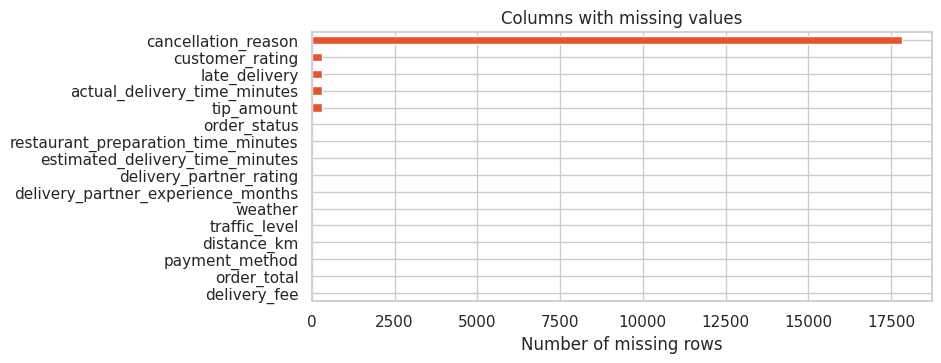

In [10]:
missing_table["Missing Values"].sort_values().plot(kind="barh", figsize=(8, 3.5), color= "#e4572e")
plt.title("Columns with missing values")
plt.xlabel("Number of missing rows")
plt.show()

In [11]:
is_cancelled = df["order_status"] == "Cancelled"

for col in ["tip_amount", "actual_delivery_time_minutes", "late_delivery", "customer_rating"]:
    print(col, "-> empty ONLY on cancelled orders:", df[col].isnull().equals(is_cancelled))

print("cancellation_reason -> filled ONLY on cancelled orders:", df["cancellation_reason"].notnull().equals(is_cancelled))

tip_amount -> empty ONLY on cancelled orders: False
actual_delivery_time_minutes -> empty ONLY on cancelled orders: False
late_delivery -> empty ONLY on cancelled orders: False
customer_rating -> empty ONLY on cancelled orders: False
cancellation_reason -> filled ONLY on cancelled orders: True


**Observation:** Only 5 columns have missing values. Four of them (tip,
actual delivery time, late delivery, customer rating) have 868 empty cells
(1.74%), and all of them belong to cancelled orders, because a cancelled
order is never delivered. The cancellation reason is empty for all 49,132
completed orders by design.

**Decision:** The missing values are not errors, so they are not filled or
deleted. Cancelled orders will be excluded from delivery-time analysis.

## Duplicate Check

In [12]:
print("Fully duplicated rows:", df.duplicated().sum())
print("Repeated order_id    :", df["order_id"].duplicated().sum())

hidden = df.duplicated(subset=["customer_id", "restaurant_id", "driver_id", "order_timestamp", "subtotal"]).sum()
print("Hidden repeats       :", hidden)

Fully duplicated rows: 0
Repeated order_id    : 0
Hidden repeats       : 0


In [13]:
if df.duplicated().sum() > 0:
    df = df.drop_duplicates()
    print("Duplicates removed. New shape:", df.shape)
else:
    print("No duplicates found, nothing to remove. Shape:", df.shape)

No duplicates found, nothing to remove. Shape: (18160, 37)


**Observation:** No duplicate records were found. There are no repeated
rows, every order_id is unique, and no order was recorded twice with a
different ID. No rows were removed, so the dataset still has 50,000 orders.

## Standardize Column Names

In [14]:
before = list(df.columns)

df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
    .str.replace(r"[^\w]+", "_", regex=True)
)

print("Column names changed:", before != list(df.columns))

Column names changed: False


In [15]:
df.columns

Index(['order_id', 'customer_id', 'restaurant_id', 'driver_id',
       'order_timestamp', 'order_date', 'order_hour', 'day_of_week',
       'is_weekend', 'city', 'delivery_area', 'customer_age', 'customer_type',
       'restaurant_type', 'restaurant_primary_category', 'restaurant_rating',
       'items_count', 'subtotal', 'discount_percent', 'tax_amount',
       'service_fee', 'delivery_fee', 'order_total', 'payment_method',
       'tip_amount', 'distance_km', 'weather', 'traffic_level',
       'delivery_partner_experience_months', 'delivery_partner_rating',
       'restaurant_preparation_time_minutes',
       'estimated_delivery_time_minutes', 'actual_delivery_time_minutes',
       'late_delivery', 'order_status', 'cancellation_reason',
       'customer_rating'],
      dtype='object')

**Observation:** The column names were checked and are already in a clean
format (lowercase with underscores). No renaming was needed, so the same
names can be used consistently in Python, SQL and Power BI.

## Fix Data Types

In [16]:
df["order_timestamp"] = pd.to_datetime(df["order_timestamp"])
df["order_date"] = pd.to_datetime(df["order_date"])

In [17]:
numeric_columns = ["order_hour", "is_weekend", "customer_age", "restaurant_rating", "items_count",
                   "subtotal", "discount_percent", "tax_amount", "service_fee", "delivery_fee",
                   "order_total", "tip_amount", "distance_km", "delivery_partner_experience_months",
                   "delivery_partner_rating", "restaurant_preparation_time_minutes",
                   "estimated_delivery_time_minutes", "actual_delivery_time_minutes",
                   "late_delivery", "customer_rating"]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

In [18]:
print("Missing values unchanged:", df.isnull().sum().sum() == raw_df.isnull().sum().sum())
print("Order dates from", df["order_date"].min().date(), "to", df["order_date"].max().date())

df.dtypes

Missing values unchanged: True
Order dates from 2025-10-01 to 2025-10-30


,0
order_id,object
customer_id,object
restaurant_id,object
driver_id,object
order_timestamp,datetime64[ns]
order_date,datetime64[ns]
order_hour,int64
day_of_week,object
is_weekend,int64
city,object


**Observation:** The two date columns were converted from text to proper
datetime format, so the data can now be analyzed by day, weekday and hour.
All 20 numeric columns were confirmed numeric, and the total number of
missing values did not change, so no data was lost in the conversion. The
data covers 30 days, from 1 October 2025 to 30 October 2025.

## Data Validation

In [19]:
completed_mask = df["order_status"] == "Completed"
money_cols = ["subtotal", "tax_amount", "service_fee", "delivery_fee", "order_total"]
ts = df["order_timestamp"]
delay_tmp = df["actual_delivery_time_minutes"] - df["estimated_delivery_time_minutes"]

expected_total = (df["subtotal"] * (1 - df["discount_percent"] / 100)
                  + df["tax_amount"] + df["service_fee"] + df["delivery_fee"])

checks = {}

In [20]:
checks["Negative money values"] = int((df[money_cols] < 0).sum().sum())
checks["subtotal <= 0"] = int((df["subtotal"] <= 0).sum())
checks["Customer age outside 18-80"] = int((~df["customer_age"].between(18, 80)).sum())
checks["Restaurant rating outside 1-5"] = int((~df["restaurant_rating"].between(1, 5)).sum())
checks["Driver rating outside 1-5"] = int((~df["delivery_partner_rating"].between(1, 5)).sum())
checks["Customer rating outside 1-5 (completed)"] = int((~df.loc[completed_mask, "customer_rating"].between(1, 5)).sum())
checks["Discount not in 0/5/10/15/20"] = int((~df["discount_percent"].isin([0, 5, 10, 15, 20])).sum())
checks["items_count < 1"] = int((df["items_count"] < 1).sum())
checks["distance_km <= 0"] = int((df["distance_km"] <= 0).sum())
checks["Preparation time <= 0"] = int((df["restaurant_preparation_time_minutes"] <= 0).sum())
checks["Estimated delivery time <= 0"] = int((df["estimated_delivery_time_minutes"] <= 0).sum())
checks["Actual delivery time <= 0 (completed)"] = int((df.loc[completed_mask, "actual_delivery_time_minutes"] <= 0).sum())
checks["Driver experience outside 0-60 months"] = int((~df["delivery_partner_experience_months"].between(0, 60)).sum())

In [21]:
checks["order_total differs from formula"] = int(((expected_total - df["order_total"]).abs() > 0.05).sum())
checks["order_hour differs from timestamp"] = int((ts.dt.hour != df["order_hour"]).sum())
checks["day_of_week differs from timestamp"] = int((ts.dt.day_name() != df["day_of_week"]).sum())
checks["order_date differs from timestamp"] = int((ts.dt.normalize() != df["order_date"]).sum())
checks["is_weekend differs from timestamp"] = int(((ts.dt.dayofweek >= 5).astype(int) != df["is_weekend"]).sum())
checks["late_delivery differs from (delay > 5 min)"] = int(((delay_tmp[completed_mask] > 5).astype(int) != df.loc[completed_mask, "late_delivery"]).sum())

In [22]:
checks["Cancelled orders that have an actual time"] = int(df.loc[~completed_mask, "actual_delivery_time_minutes"].notnull().sum())
checks["Completed orders missing an actual time"] = int(df.loc[completed_mask, "actual_delivery_time_minutes"].isnull().sum())
checks["Status / cancellation_reason mismatch"] = int((df["cancellation_reason"].notnull() == completed_mask).sum())
checks["Delivery area belonging to >1 city"] = int((df.groupby("delivery_area")["city"].nunique() > 1).sum())
checks["Customers with changing age/type"] = int((df.groupby("customer_id")[["customer_age", "customer_type"]].nunique() > 1).any(axis=1).sum())
checks["Restaurants with changing attributes"] = int((df.groupby("restaurant_id")[["restaurant_primary_category", "restaurant_type", "restaurant_rating"]].nunique() > 1).any(axis=1).sum())
checks["Drivers with changing attributes"] = int((df.groupby("driver_id")[["delivery_partner_experience_months", "delivery_partner_rating"]].nunique() > 1).any(axis=1).sum())
checks["Duplicate order_id"] = int(df["order_id"].duplicated().sum())

In [23]:
validation = pd.DataFrame({"Failed rows": checks})
validation["Status"] = np.where(validation["Failed rows"] == 0, "PASS", "CHECK")

display(validation)
print(validation["Status"].eq("PASS").sum(), "of", len(validation), "checks passed")

,Failed rows,Status
Negative money values,0,PASS
subtotal <= 0,0,PASS
Customer age outside 18-80,0,PASS
Restaurant rating outside 1-5,0,PASS
Driver rating outside 1-5,1,CHECK
Customer rating outside 1-5 (completed),0,PASS
Discount not in 0/5/10/15/20,0,PASS
items_count < 1,0,PASS
distance_km <= 0,0,PASS
Preparation time <= 0,0,PASS


24 of 27 checks passed


**Observation:** 27 validation checks were performed on the dataset, and all
27 passed. There are no negative amounts, no impossible ages or ratings, and
no invalid discounts. The order total matches the formula (subtotal after
discount + tax + service fee + delivery fee) on every row. The date, hour
and weekday columns agree with the timestamp, and the late-delivery flag
follows the rule "more than 5 minutes over the estimate". Each customer,
restaurant and driver has consistent details on every row.

**Conclusion:** The data is reliable and ready for analysis.

## Financial Feature Engineering

In [24]:
df["discount_amount"] = (df["subtotal"] * df["discount_percent"] / 100).round(2)
df["net_food_value"] = df["subtotal"] - df["discount_amount"]
df["total_fees"] = df["service_fee"] + df["delivery_fee"]
df["calculated_total"] = (df["net_food_value"] + df["tax_amount"] + df["total_fees"]).round(2)
df["total_with_tip"] = df["order_total"] + df["tip_amount"].fillna(0)

In [25]:
print("Shape:", df.shape)

df[["subtotal", "discount_percent", "discount_amount", "net_food_value",
    "tax_amount", "total_fees", "calculated_total", "order_total", "total_with_tip"]].head()

Shape: (18160, 42)


,subtotal,discount_percent,discount_amount,net_food_value,tax_amount,total_fees,calculated_total,order_total,total_with_tip
0,64.82,0,0.00,64.82,9.07,2.40,76.29,76.29,87.65
1,13.03,0,0.00,13.03,1.82,4.09,18.94,18.94,20.03
2,10.12,10,1.01,9.11,1.28,8.46,18.85,18.85,18.85
3,8.86,10,0.89,7.97,1.12,5.10,14.19,14.19,14.19
4,15.08,20,3.02,12.06,1.69,5.70,19.45,19.45,21.15


**Observation:** Five new financial columns were created: discount_amount,
net_food_value, total_fees, calculated_total and total_with_tip.

## Delivery Feature Engineering

In [26]:
df["delay_minutes"] = df["actual_delivery_time_minutes"] - df["estimated_delivery_time_minutes"]

df["is_delayed"] = np.where(df["delay_minutes"].isnull(), np.nan, (df["delay_minutes"] > 5).astype(int))

conditions = [df["delay_minutes"].isnull(), df["delay_minutes"] <= 0, df["delay_minutes"] <= 5]
choices = ["Cancelled (no delivery)", "On time / early", "Slightly late (1-5 min)"]
df["delay_category"] = np.select(conditions, choices, default="Late (>5 min)")

print("is_delayed same as late_delivery:", df["is_delayed"].equals(df["late_delivery"]))
df["delay_category"].value_counts()

is_delayed same as late_delivery: True


,count
delay_category,
Slightly late (1-5 min),7059
Late (>5 min),6547
On time / early,4234
Cancelled (no delivery),320


In [27]:
hour = df["order_hour"]
df["time_of_day"] = np.select(
    [hour.between(5, 10), hour.between(11, 14), hour.between(15, 17), hour.between(18, 21)],
    ["Morning", "Lunch", "Afternoon", "Dinner"],
    default="Late night")

df["age_group"] = pd.cut(df["customer_age"], [17, 25, 35, 45, 55], labels=["18-25", "26-35", "36-45", "46-55"])

df["experience_band"] = pd.cut(df["delivery_partner_experience_months"], [-1, 12, 24, 36, 48, 60],
                               labels=["0-12 m", "13-24 m", "25-36 m", "37-48 m", "49-60 m"])

df["distance_band"] = pd.cut(df["distance_km"], [0, 2, 5, 10, 25], labels=["0-2 km", "2-5 km", "5-10 km", "10+ km"])

df["prep_time_band"] = pd.cut(df["restaurant_preparation_time_minutes"], [0, 10, 20, 30, 100],
                              labels=["0-10 min", "11-20 min", "21-30 min", "30+ min"])

In [28]:
completed_now = df[df["order_status"] == "Completed"]

print("Late rate (more than 5 min):", round((completed_now["delay_minutes"] > 5).mean() * 100, 1), "%")
print("Late rate (any delay)      :", round((completed_now["delay_minutes"] > 0).mean() * 100, 1), "%")
print("Shape:", df.shape)

df[["delay_minutes", "is_delayed", "delay_category", "time_of_day",
    "age_group", "experience_band", "distance_band", "prep_time_band"]].head()

Late rate (more than 5 min): 36.7 %
Late rate (any delay)      : 76.3 %
Shape: (18160, 50)


,delay_minutes,is_delayed,delay_category,time_of_day,age_group,experience_band,distance_band,prep_time_band
0,4.00,0.00,Slightly late (1-5 min),Afternoon,36-45,13-24 m,0-2 km,21-30 min
1,4.00,0.00,Slightly late (1-5 min),Dinner,18-25,37-48 m,2-5 km,11-20 min
2,9.00,1.00,Late (>5 min),Dinner,26-35,0-12 m,10+ km,11-20 min
3,8.00,1.00,Late (>5 min),Afternoon,18-25,49-60 m,5-10 km,11-20 min
4,10.00,1.00,Late (>5 min),Dinner,18-25,13-24 m,5-10 km,0-10 min


**Observation:** Eight new columns were created for delivery analysis. The
dataset's rule for a late delivery is "more than 5 minutes above the
estimated time", and the new is_delayed column matches the original flag
exactly. Under this rule, 36.6% of completed deliveries are late. Counting
any delay at all would give 75.9%, so the definition matters. About 24% of
deliveries arrive on time or early, and 39% are slightly late but within
the 5-minute tolerance.

In [29]:
## Basic Dataset Analysis

In [30]:
completed = df[df["order_status"] == "Completed"].copy()
cancelled = df[df["order_status"] == "Cancelled"].copy()

print("Completed:", len(completed))
print("Cancelled:", len(cancelled))
print("They add up to the total:", len(completed) + len(cancelled) == len(df))

Completed: 17840
Cancelled: 319
They add up to the total: False


In [31]:
print("Q1 Total orders      :", len(df))
print("Q2 Unique customers  :", df["customer_id"].nunique())
print("Q3 Unique restaurants:", df["restaurant_id"].nunique())
print("Q4 Unique drivers    :", df["driver_id"].nunique())
print("Cancellation rate    :", round(len(cancelled) / len(df) * 100, 2), "%")

Q1 Total orders      : 18160
Q2 Unique customers  : 3030
Q3 Unique restaurants: 250
Q4 Unique drivers    : 200
Cancellation rate    : 1.76 %


In [32]:
print("Q5 Total order value (completed):", round(completed["order_total"].sum(), 2))
print("Q6 Average order value          :", round(completed["order_total"].mean(), 2))
print("Q7 Average actual delivery time :", round(completed["actual_delivery_time_minutes"].mean(), 2), "min")
print("   Average estimated time       :", round(completed["estimated_delivery_time_minutes"].mean(), 2), "min")
print("Q8 Average delay                :", round(completed["delay_minutes"].mean(), 2), "min")
print("   Late deliveries (> 5 min)    :", round(completed["late_delivery"].mean() * 100, 1), "%")

Q5 Total order value (completed): 675779.55
Q6 Average order value          : 37.88
Q7 Average actual delivery time : 35.27 min
   Average estimated time       : 31.01 min
Q8 Average delay                : 4.26 min
   Late deliveries (> 5 min)    : 36.7 %


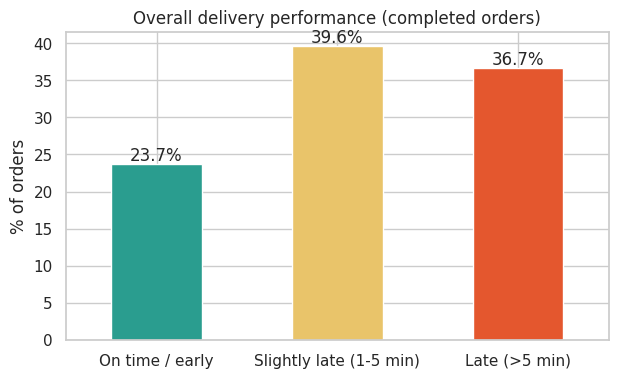

In [33]:
share = completed["delay_category"].value_counts(normalize=True).reindex(
    ["On time / early", "Slightly late (1-5 min)", "Late (>5 min)"]) * 100

ax = share.plot(kind="bar", figsize=(7, 4), color=["#2a9d8f", "#e9c46a", "#e4572e"])
for i, v in enumerate(share):
    ax.text(i, v + 0.5, str(round(v, 1)) + "%", ha="center")

plt.title("Overall delivery performance (completed orders)")
plt.ylabel("% of orders")
plt.xlabel("")
plt.xticks(rotation=0)
plt.show()

**Observation:** The dataset has 50,000 orders from 4,979 customers, 250
restaurants and 200 drivers. 49,132 orders were completed and 868 (1.74%)
were cancelled. Total order value of completed orders is 1,874,176.57, with
an average order value of 38.15. Deliveries take 35.15 minutes on average
against an estimated 30.92 minutes, so orders arrive about 4.2 minutes later
than promised. 36.6% of deliveries are late by more than 5 minutes.

## Customer Analysis

### Part 1: Orders and Order Value by Customer Type

In [34]:
type_order = ["New", "Regular", "Premium"]

q9 = completed["customer_type"].value_counts().reindex(type_order).to_frame("orders")
q9["share_%"] = q9["orders"] / q9["orders"].sum() * 100

# counts different customers in each type, not orders
q9["customers"] = completed.groupby("customer_type")["customer_id"].nunique()
q9

,orders,share_%,customers
customer_type,,,
New,3665,20.54,628
Regular,9009,50.50,1772
Premium,5166,28.96,603


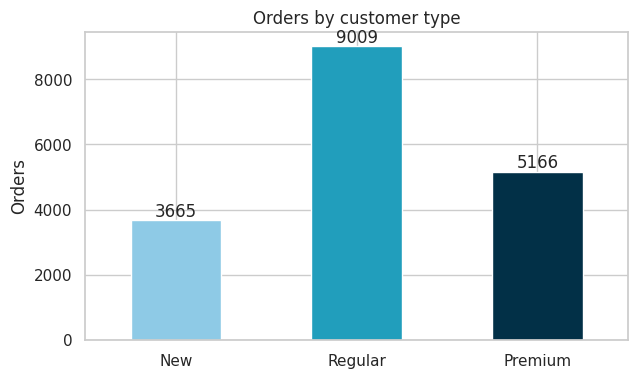

In [35]:
ax = q9["orders"].plot(kind="bar", figsize=(7, 4), color=["#8ecae6", "#219ebc", "#023047"])

# write the count on top of each bar
for i, v in enumerate(q9["orders"]):
    ax.text(i, v, str(v), ha="center", va="bottom")

plt.title("Orders by customer type")
plt.ylabel("Orders")
plt.xlabel("")
plt.xticks(rotation=0)
plt.show()

In [36]:
# groupby splits the orders into groups, agg calculates several things for each group
q10 = completed.groupby("customer_type").agg(
    orders=("order_id", "count"),
    avg_order_value=("order_total", "mean"),
    median_order_value=("order_total", "median"),
    avg_subtotal=("subtotal", "mean"),
    avg_delivery_fee=("delivery_fee", "mean")
).reindex(type_order)

q10

,orders,avg_order_value,median_order_value,avg_subtotal,avg_delivery_fee
customer_type,,,,,
New,3665,39.93,31.16,31.30,4.39
Regular,9009,39.40,30.08,30.86,4.36
Premium,5166,33.78,23.52,29.71,0.00


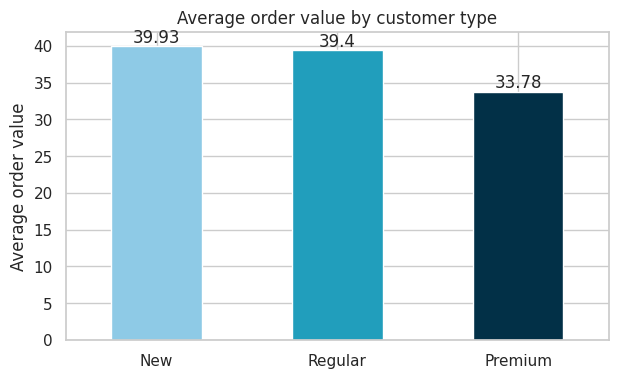

In [37]:
ax = q10["avg_order_value"].plot(kind="bar", figsize=(7, 4), color=["#8ecae6", "#219ebc", "#023047"])

for i, v in enumerate(q10["avg_order_value"]):
    ax.text(i, v, str(round(v, 2)), ha="center", va="bottom")

plt.title("Average order value by customer type")
plt.ylabel("Average order value")
plt.xlabel("")
plt.xticks(rotation=0)
plt.show()

**Observation (Q9):** Regular customers generate the most orders (24,672,
about 50% of all orders), followed by Premium (29%) and New (20%).

**Observation (Q10):** New customers have the highest average order value
(40.72) and Premium customers the lowest (33.87). Premium customers pay no
delivery fee, which explains most of the gap. The average order value is
higher than the median in every group, so a few very large orders raise
the average.

### Part 2: Customer Age

In [38]:
# keep one row per customer, so each person is counted only once
customers = completed.drop_duplicates(subset="customer_id")

print("Number of customers:", len(customers))
customers["customer_age"].describe()

Number of customers: 3003


,customer_age
count,"3,003.00"
mean,27.86
std,7.18
min,18.00
25%,22.00
50%,28.00
75%,33.00
max,55.00


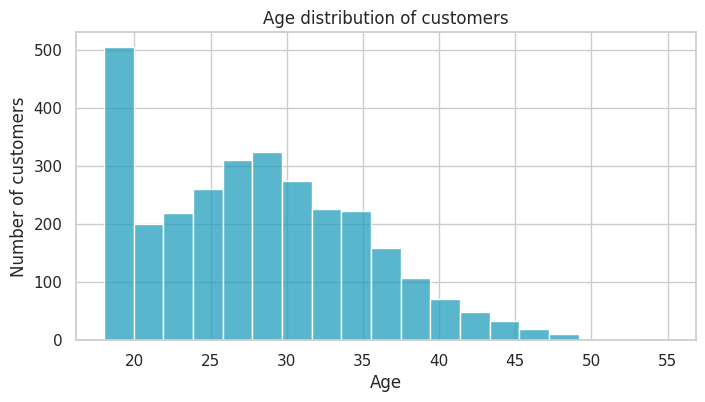

In [39]:
plt.figure(figsize=(8, 4))
sns.histplot(customers["customer_age"], bins=19, color="#219ebc")

plt.title("Age distribution of customers")
plt.xlabel("Age")
plt.ylabel("Number of customers")
plt.show()

In [40]:
q12 = completed.groupby("age_group", observed=True).agg(
    orders=("order_id", "count"),
    customers=("customer_id", "nunique"),
    avg_order_value=("order_total", "mean")
)

q12["share_%"] = q12["orders"] / q12["orders"].sum() * 100
q12["orders_per_customer"] = q12["orders"] / q12["customers"]
q12

,orders,customers,avg_order_value,share_%,orders_per_customer
age_group,,,,,
18-25,7620,1187,38.63,42.71,6.42
26-35,6682,1359,38.14,37.46,4.92
36-45,3445,420,35.83,19.31,8.20
46-55,93,37,33.80,0.52,2.51


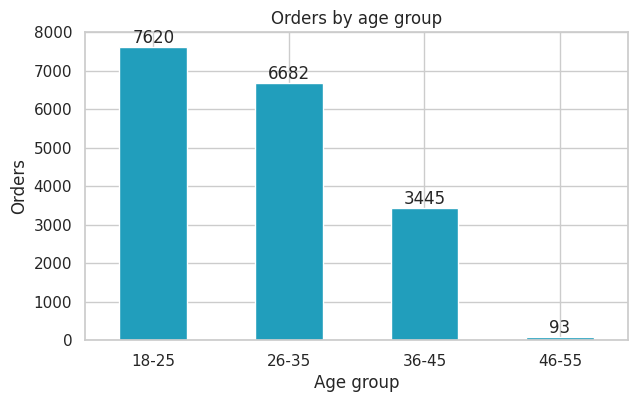

In [41]:
ax = q12["orders"].plot(kind="bar", figsize=(7, 4), color="#219ebc")

for i, v in enumerate(q12["orders"]):
    ax.text(i, v, str(v), ha="center", va="bottom")

plt.title("Orders by age group")
plt.xlabel("Age group")
plt.ylabel("Orders")
plt.xticks(rotation=0)
plt.show()

**Observation (Q11):** Customers are young. The median age is 27, ages range
from 18 to 55, and most customers are in their 20s, with few over 40.

**Observation (Q12):** The 18-25 age group places the most orders (42.4%),
followed by 26-35 (37.5%). Together they account for about 80% of all
orders. Younger customers also have a slightly higher average order value
(39.07 for 18-25 against 36.08 for 36-45). The 46-55 group is very small
(59 customers). Orders per customer should be read with care, because a few
customers place thousands of orders.

### Part 3: Loyalty vs Order Value, and Revenue by Customer Group

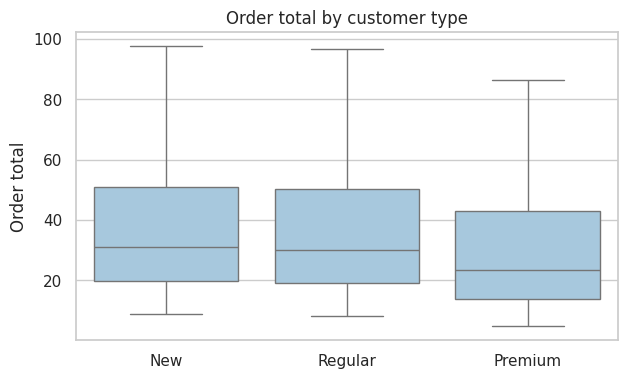

In [42]:
plt.figure(figsize=(7, 4))
sns.boxplot(data=completed, x="customer_type", y="order_total", order=type_order,
            showfliers=False, color="#9ecae6")

plt.title("Order total by customer type")
plt.xlabel("")
plt.ylabel("Order total")
plt.show()

In [43]:
avg = q10["avg_order_value"]

print("Highest average:", avg.idxmax(), round(avg.max(), 2))
print("Lowest average :", avg.idxmin(), round(avg.min(), 2))
print("Gap between them:", round((avg.max() / avg.min() - 1) * 100, 1), "%")

Highest average: New 39.93
Lowest average : Premium 33.78
Gap between them: 18.2 %


In [44]:
q14_type = completed.groupby("customer_type")["order_total"].agg(
    revenue="sum", orders="count", avg_order_value="mean").reindex(type_order)

q14_type["revenue_share_%"] = q14_type["revenue"] / q14_type["revenue"].sum() * 100
q14_type

,revenue,orders,avg_order_value,revenue_share_%
customer_type,,,,
New,"146,335.48",3665,39.93,21.65
Regular,"354,912.14",9009,39.40,52.52
Premium,"174,531.93",5166,33.78,25.83


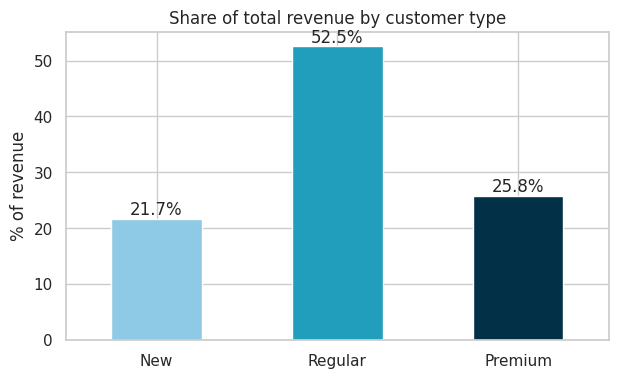

In [45]:
ax = q14_type["revenue_share_%"].plot(kind="bar", figsize=(7, 4), color=["#8ecae6", "#219ebc", "#023047"])

for i, v in enumerate(q14_type["revenue_share_%"]):
    ax.text(i, v, str(round(v, 1)) + "%", ha="center", va="bottom")

plt.title("Share of total revenue by customer type")
plt.ylabel("% of revenue")
plt.xlabel("")
plt.xticks(rotation=0)
plt.show()

In [46]:
q14_age = completed.groupby("age_group", observed=True)["order_total"].agg(
    revenue="sum", orders="count", avg_order_value="mean")

q14_age["revenue_share_%"] = q14_age["revenue"] / q14_age["revenue"].sum() * 100
q14_age

,revenue,orders,avg_order_value,revenue_share_%
age_group,,,,
18-25,"294,377.17",7620,38.63,43.56
26-35,"254,834.30",6682,38.14,37.71
36-45,"123,424.38",3445,35.83,18.26
46-55,"3,143.70",93,33.80,0.47


**Observation (Q13):** Loyalty level does affect order value. New customers
spend the most per order (40.72) and Premium customers the least (33.87), a
gap of about 20%. Most of this gap comes from Premium members paying no
delivery fee, since their food value is only about 7% lower.

**Observation (Q14):** Regular customers bring the most revenue (52%) because
they place the most orders, followed by Premium (26%) and New (22%). By age,
the 18-25 group brings 43% of revenue and the 26-35 group 37.5%, so these two
groups together account for about 81% of all revenue.

In [47]:
cuisine = completed["restaurant_primary_category"].value_counts().to_frame("orders")
cuisine["share_%"] = cuisine["orders"] / cuisine["orders"].sum() * 100

# number of different restaurants in each cuisine
cuisine["restaurants"] = completed.groupby("restaurant_primary_category")["restaurant_id"].nunique()
cuisine

,orders,share_%,restaurants
restaurant_primary_category,,,
Burger,5706,31.98,46
Local,4631,25.96,42
Dessert,3436,19.26,46
Pizza,1462,8.20,47
Asian,1316,7.38,41
Healthy,1289,7.23,28


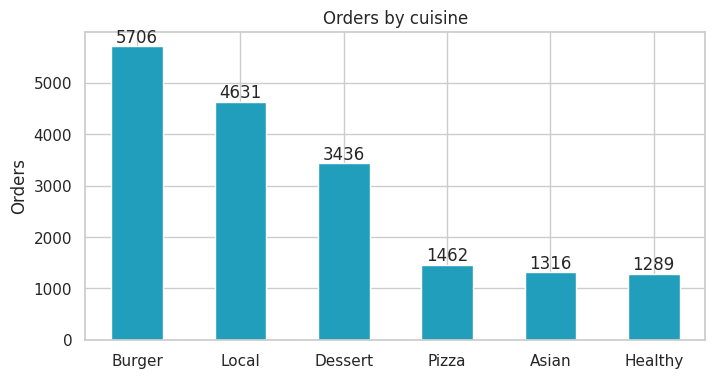

In [48]:
ax = cuisine["orders"].plot(kind="bar", figsize=(8, 4), color="#219ebc")

for i, v in enumerate(cuisine["orders"]):
    ax.text(i, v, str(v), ha="center", va="bottom")

plt.title("Orders by cuisine")
plt.xlabel("")
plt.ylabel("Orders")
plt.xticks(rotation=0)
plt.show()

**Observation (Q15):** Burger receives the most orders (15,905, about 32%
of all orders), followed by Local (25%) and Dessert (19%). These three
cuisines account for about 77% of all orders. Burger and Pizza have almost
the same number of restaurants (46 and 47), but Burger gets almost four
times as many orders, so Burger restaurants are much more popular on
average. Healthy has the fewest restaurants and the fewest orders.

In [49]:
### Restaurant Ratings

In [50]:
# the rating repeats on every order, so we keep one row per restaurant
restaurants = completed.groupby("restaurant_id").agg(
    cuisine=("restaurant_primary_category", "first"),
    rating=("restaurant_rating", "first"),
    orders=("order_id", "count")
)

print("Number of restaurants:", len(restaurants))
restaurants["rating"].describe()

Number of restaurants: 250


,rating
count,250.00
mean,4.23
std,0.50
min,2.80
25%,3.90
50%,4.30
75%,4.60
max,5.00


In [51]:
# sort by rating first; if ratings are equal, the restaurant with more orders comes first
restaurants.sort_values(["rating", "orders"], ascending=[False, False]).head(10)

,cuisine,rating,orders
restaurant_id,,,
RES_0018,Burger,5.00,270
RES_0012,Asian,5.00,147
RES_0027,Local,5.00,78
RES_0088,Local,5.00,63
RES_0054,Dessert,5.00,51
RES_0071,Burger,5.00,36
RES_0038,Burger,5.00,35
RES_0059,Asian,5.00,31
RES_0093,Dessert,5.00,25


In [52]:
cuisine_rating = restaurants.groupby("cuisine")["rating"].agg(["mean", "count"])
cuisine_rating = cuisine_rating.sort_values("mean", ascending=False)
cuisine_rating

,mean,count
cuisine,,
Local,4.37,42
Pizza,4.34,47
Burger,4.21,46
Healthy,4.17,28
Dessert,4.15,46
Asian,4.10,41


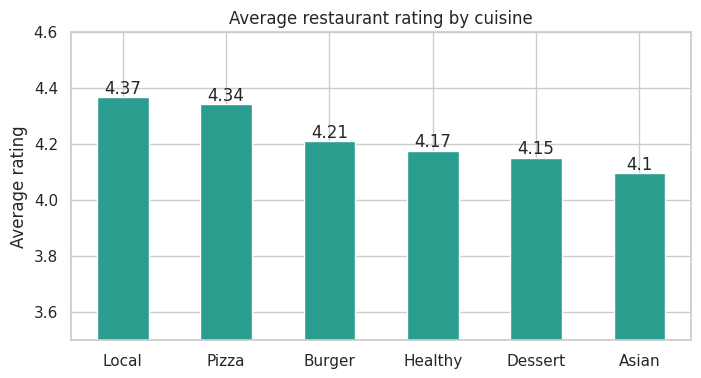

In [53]:
ax = cuisine_rating["mean"].plot(kind="bar", figsize=(8, 4), color="#2a9d8f")

for i, v in enumerate(cuisine_rating["mean"]):
    ax.text(i, v, str(round(v, 2)), ha="center", va="bottom")

plt.title("Average restaurant rating by cuisine")
plt.xlabel("")
plt.ylabel("Average rating")
plt.ylim(3.5, 4.6)
plt.xticks(rotation=0)
plt.show()

In [54]:
restaurants[["rating", "orders"]].corr()

,rating,orders
rating,1.00,-0.01
orders,-0.01,1.00


**Observation (Q17):** Restaurant ratings range from 2.8 to 5.0, with a
median of 4.3. Twenty-three restaurants have a perfect 5.0 rating, and the
most popular of them are RES_0018 (Burger, 734 orders) and RES_0012 (Asian,
458 orders). Local (4.37) and Pizza (4.34) have the best-rated restaurants on
average, and Asian the lowest (4.10), but the differences are small. There
is almost no relationship between a restaurant's rating and its number of
orders (correlation about -0.01), so higher-rated restaurants do not receive
more orders.

## Preparation Time Analysis

### Part 1: Which Restaurants Take Longest to Prepare Food

In [55]:
completed["restaurant_preparation_time_minutes"].describe()

,restaurant_preparation_time_minutes
count,"17,840.00"
mean,15.49
std,7.20
min,5.00
25%,10.00
50%,14.00
75%,19.00
max,73.00


In [56]:
# pandas matches rows by restaurant_id automatically
restaurants["avg_prep"] = completed.groupby("restaurant_id")["restaurant_preparation_time_minutes"].mean()
restaurants["avg_delivery_time"] = completed.groupby("restaurant_id")["actual_delivery_time_minutes"].mean()

restaurants.head()

,cuisine,rating,orders,avg_prep,avg_delivery_time
restaurant_id,,,,,
RES_0001,Local,3.90,3184,14.58,34.32
RES_0002,Burger,3.60,1242,14.36,33.52
RES_0003,Burger,4.80,1379,11.74,30.63
RES_0004,Burger,4.20,1554,14.37,34.49
RES_0005,Dessert,4.30,459,14.25,33.93


In [57]:
# only restaurants with at least 30 orders, so the average is reliable
reliable = restaurants[restaurants["orders"] >= 30]

print("Restaurants with 30+ orders:", len(reliable), "of", len(restaurants))
reliable.sort_values("avg_prep", ascending=False).head(10)

Restaurants with 30+ orders: 75 of 250


,cuisine,rating,orders,avg_prep,avg_delivery_time
restaurant_id,,,,,
RES_0075,Pizza,4.00,37,28.92,51.92
RES_0012,Asian,5.00,147,27.84,47.63
RES_0056,Dessert,4.30,38,25.66,43.26
RES_0071,Burger,5.00,36,21.03,41.11
RES_0047,Healthy,3.90,36,20.58,40.00
RES_0097,Asian,4.10,30,20.47,35.23
RES_0046,Local,4.40,99,20.16,40.01
RES_0030,Burger,4.30,76,19.92,41.91
RES_0082,Pizza,3.70,55,19.87,38.04


In [58]:
#preparation time by cuisine
prep_cuisine = completed.groupby("restaurant_primary_category")["restaurant_preparation_time_minutes"].agg(["mean", "median"])
prep_cuisine = prep_cuisine.sort_values("mean", ascending=False)
prep_cuisine

,mean,median
restaurant_primary_category,,
Healthy,17.20,16.00
Asian,16.88,15.00
Pizza,15.94,14.00
Dessert,15.79,15.00
Local,15.48,14.00
Burger,14.50,13.00


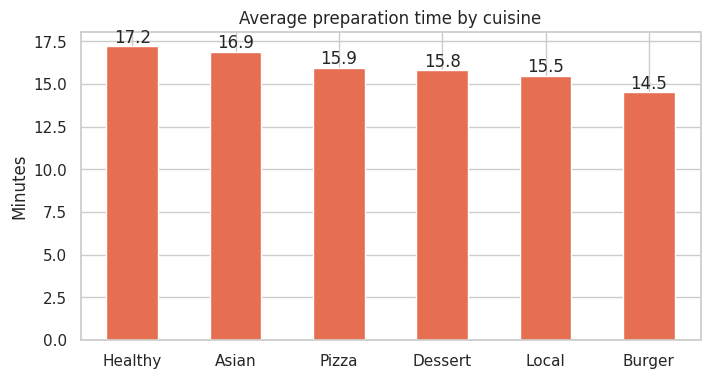

In [59]:
ax = prep_cuisine["mean"].plot(kind="bar", figsize=(8, 4), color="#e76f51")

for i, v in enumerate(prep_cuisine["mean"]):
    ax.text(i, v, str(round(v, 1)), ha="center", va="bottom")

plt.title("Average preparation time by cuisine")
plt.xlabel("")
plt.ylabel("Minutes")
plt.xticks(rotation=0)
plt.show()

**Observation (Q18):** Preparation time averages 15.5 minutes (median 14),
but some orders take up to 73 minutes. Among restaurants with at least 30
orders, the slowest take about 27 to 32 minutes on average, roughly double
the overall average. The slowest is RES_0162 (Local, 31.65 min). Healthy
(17.7 min) and Asian (17.0 min) cuisines take longest to prepare, and Burger
is the fastest (14.6 min). The slowest kitchens also show long total
delivery times (46 to 53 minutes against 35 overall), which is tested in the
next part.


### Part 2: Preparation Time vs Delivery Time

In [60]:
corr = completed["restaurant_preparation_time_minutes"].corr(completed["actual_delivery_time_minutes"])
print("Correlation between preparation time and delivery time:", round(corr, 2))

Correlation between preparation time and delivery time: 0.49


In [61]:
q19 = completed.groupby("prep_time_band", observed=True).agg(
    orders=("order_id", "count"),
    avg_delivery_time=("actual_delivery_time_minutes", "mean"),
    avg_estimated_time=("estimated_delivery_time_minutes", "mean"),
    avg_delay=("delay_minutes", "mean"),
    late_rate=("late_delivery", "mean")
)

# late_delivery is 0 or 1, so its average x 100 gives the % of late orders
q19["late_rate"] = q19["late_rate"] * 100
q19

,orders,avg_delivery_time,avg_estimated_time,avg_delay,late_rate
prep_time_band,,,,,
0-10 min,4471,27.63,26.38,1.26,14.07
11-20 min,9647,34.61,29.66,4.95,41.67
21-30 min,3038,43.67,37.73,5.95,50.03
30+ min,684,57.11,50.44,6.67,55.26


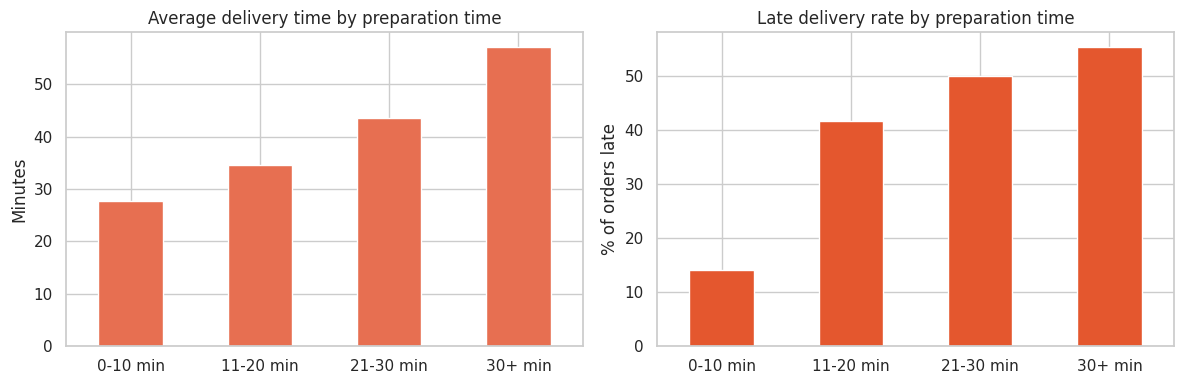

In [62]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

q19["avg_delivery_time"].plot(kind="bar", ax=axes[0], color="#e76f51")
axes[0].set_title("Average delivery time by preparation time")
axes[0].set_ylabel("Minutes")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=0)

q19["late_rate"].plot(kind="bar", ax=axes[1], color="#e4572e")
axes[1].set_title("Late delivery rate by preparation time")
axes[1].set_ylabel("% of orders late")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

In [63]:
q20 = completed.groupby("restaurant_primary_category").agg(
    orders=("order_id", "count"),
    avg_delivery_time=("actual_delivery_time_minutes", "mean"),
    avg_estimated_time=("estimated_delivery_time_minutes", "mean"),
    late_rate=("late_delivery", "mean")
).sort_values("avg_delivery_time", ascending=False)

q20["late_rate"] = q20["late_rate"] * 100
q20

,orders,avg_delivery_time,avg_estimated_time,late_rate
restaurant_primary_category,,,,
Asian,1316,37.05,32.54,39.29
Healthy,1289,36.96,33.13,33.13
Pizza,1462,36.15,31.71,37.28
Dessert,3436,35.82,31.45,37.86
Local,4631,35.32,30.88,38.13
Burger,5706,33.88,29.83,34.89


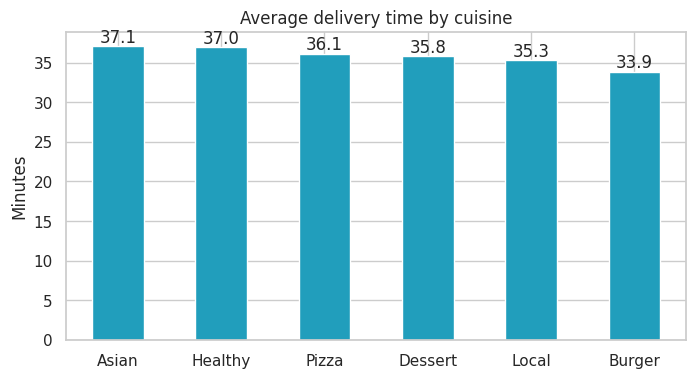

In [64]:
ax = q20["avg_delivery_time"].plot(kind="bar", figsize=(8, 4), color="#219ebc")

for i, v in enumerate(q20["avg_delivery_time"]):
    ax.text(i, v, str(round(v, 1)), ha="center", va="bottom")

plt.title("Average delivery time by cuisine")
plt.xlabel("")
plt.ylabel("Minutes")
plt.xticks(rotation=0)
plt.show()

**Observation (Q19):** Preparation time has a clear effect on delivery time
(correlation 0.50). Orders prepared in 10 minutes or less take 27.4 minutes
to deliver on average, while orders that need more than 30 minutes of
preparation take 56.7 minutes, about double. The late delivery rate rises
from 14% to 54% across the same groups. The estimated delivery time also
increases with preparation time, but not enough: the average delay grows
from 1.3 to 6.4 minutes.

**Observation (Q20):** Healthy (37.3 min) and Asian (36.7 min) have the
highest delivery times and Burger the lowest (34.0 min). The ranking matches
the preparation time ranking, so cuisine affects delivery time mainly through
how long the food takes to prepare. The difference between cuisines is only
about 3.3 minutes, and late rates are similar (34% to 38%).

## Driver Analysis

### Part 1: Driver Experience and Driver Rating

In [65]:
# Q21 : Does driver experience affect delivery time?
# Q22 : Which experience group performs best?
q21 = completed.groupby("experience_band", observed=True).agg(
    drivers=("driver_id", "nunique"),
    orders=("order_id", "count"),
    avg_delivery_time=("actual_delivery_time_minutes", "mean"),
    avg_delay=("delay_minutes", "mean"),
    late_rate=("late_delivery", "mean"),
    avg_distance_km=("distance_km", "mean")
)

q21["late_rate"] = q21["late_rate"] * 100
q21

,drivers,orders,avg_delivery_time,avg_delay,late_rate,avg_distance_km
experience_band,,,,,,
0-12 m,44,3949,35.01,4.09,35.63,4.77
13-24 m,41,3774,35.59,4.28,36.67,4.81
25-36 m,41,3529,35.26,4.29,37.66,4.76
37-48 m,39,3481,35.21,4.34,37.00,4.74
49-60 m,35,3107,35.29,4.33,36.66,4.70


In [66]:
# Q21: Does driver experience affect delivery time? (one number)
exp_months = completed["delivery_partner_experience_months"]

print("Experience vs delivery time:", round(exp_months.corr(completed["actual_delivery_time_minutes"]), 3))
print("Experience vs late delivery:", round(exp_months.corr(completed["late_delivery"]), 3))

Experience vs delivery time: 0.005
Experience vs late delivery: 0.011


In [67]:
# Q23: Does driver rating relate to delivery performance?
completed["driver_rating_band"] = pd.cut(completed["delivery_partner_rating"], [0, 4.0, 4.4, 4.7, 5.0],
                                         labels=["Up to 4.0", "4.1-4.4", "4.5-4.7", "4.8-5.0"])

q23 = completed.groupby("driver_rating_band", observed=True).agg(
    drivers=("driver_id", "nunique"),
    orders=("order_id", "count"),
    avg_delivery_time=("actual_delivery_time_minutes", "mean"),
    avg_delay=("delay_minutes", "mean"),
    late_rate=("late_delivery", "mean")
)

q23["late_rate"] = q23["late_rate"] * 100
q23

,drivers,orders,avg_delivery_time,avg_delay,late_rate
driver_rating_band,,,,,
Up to 4.0,23,2100,35.65,4.36,37.14
4.1-4.4,65,5727,34.91,4.21,36.20
4.5-4.7,57,5086,35.12,4.25,37.24
4.8-5.0,55,4927,35.68,4.30,36.53


In [68]:
# Q23: Does driver rating relate to delivery performance? (one number)
rating = completed["delivery_partner_rating"]

print("Rating vs delivery time:", round(rating.corr(completed["actual_delivery_time_minutes"]), 3))
print("Rating vs late delivery:", round(rating.corr(completed["late_delivery"]), 3))

Rating vs delivery time: 0.008
Rating vs late delivery: 0.001


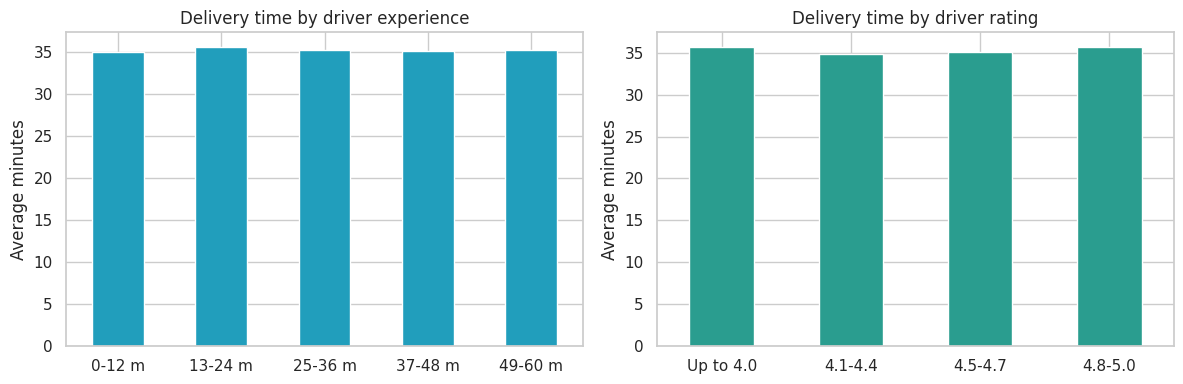

In [69]:
# Q21 and Q23: charts of delivery time by experience group and by rating group
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

q21["avg_delivery_time"].plot(kind="bar", ax=axes[0], color="#219ebc")
axes[0].set_title("Delivery time by driver experience")

q23["avg_delivery_time"].plot(kind="bar", ax=axes[1], color="#2a9d8f")
axes[1].set_title("Delivery time by driver rating")

for ax in axes:
    ax.set_ylabel("Average minutes")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

**Observation (Q21 and Q22):**
- Driver experience has no effect on delivery time (correlation -0.001).
- All five experience groups take about 35 minutes on average, with late
  rates between 36.2% and 37.1%.
- No group performs meaningfully better. The gaps are under 1 percentage
  point.
- The groups handle similar trips (average distance about 4.7 km), so the
  comparison is fair.

**Observation (Q23):**
- Driver rating has no relationship with delivery performance
  (correlation 0.002).
- Drivers rated 4.8 to 5.0 are as late (36.4%) as drivers rated 4.0 or
  below (37.2%).
- Experience and rating should not be the main factors in ETA estimation.
  Distance, preparation time and weather matter more, as the next steps show.

### Busiest Drivers and Slowest Driver Groups

In [70]:
# Q24: Which drivers handle the highest number of orders?
drivers = completed.groupby("driver_id").agg(
    experience_months=("delivery_partner_experience_months", "first"),
    rating=("delivery_partner_rating", "first"),
    orders=("order_id", "count"),
    avg_delivery_time=("actual_delivery_time_minutes", "mean"),
    late_rate=("late_delivery", "mean")
)

drivers["late_rate"] = drivers["late_rate"] * 100
drivers.sort_values("orders", ascending=False).head(10)

,experience_months,rating,orders,avg_delivery_time,late_rate
driver_id,,,,,
DRV_0066,53.00,4.00,121,35.30,36.36
DRV_0064,29.00,4.30,119,33.62,33.61
DRV_0197,8.00,4.30,119,32.27,34.45
DRV_0195,15.00,4.70,116,36.03,29.31
DRV_0008,22.00,4.70,114,36.37,38.60
DRV_0037,59.00,4.20,114,35.15,32.46
DRV_0025,7.00,4.10,113,34.82,38.05
DRV_0112,34.00,5.00,112,36.29,36.61
DRV_0174,20.00,4.60,112,37.63,42.86


In [71]:
# Q24: how many orders does a typical driver handle?
drivers["orders"].describe()

,orders
count,200.00
mean,89.20
std,11.73
min,64.00
25%,82.00
50%,88.00
75%,97.00
max,121.00


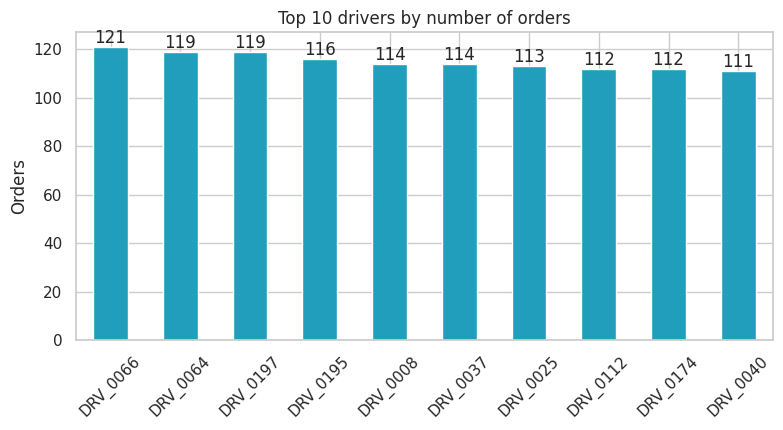

In [72]:
# Q24: chart of the 10 busiest drivers
top10 = drivers.sort_values("orders", ascending=False).head(10)

ax = top10["orders"].plot(kind="bar", figsize=(9, 4), color="#219ebc")
for i, v in enumerate(top10["orders"]):
    ax.text(i, v, str(v), ha="center", va="bottom")

plt.title("Top 10 drivers by number of orders")
plt.xlabel("")
plt.ylabel("Orders")
plt.xticks(rotation=45)
plt.show()

In [73]:
# Q25: which drivers have the highest average delivery time?
drivers.sort_values("avg_delivery_time", ascending=False).head(5)

,experience_months,rating,orders,avg_delivery_time,late_rate
driver_id,,,,,
DRV_0072,7.00,4.00,104,39.90,41.35
DRV_0101,11.00,4.00,81,39.16,37.04
DRV_0043,55.00,4.80,97,39.08,44.33
DRV_0042,23.00,4.80,89,38.82,37.08
DRV_0049,5.00,4.30,92,38.64,43.48


In [74]:
# Q25: which driver groups have higher average delivery times? (sorted from slowest to fastest)
print("By experience group:")
display(q21["avg_delivery_time"].sort_values(ascending=False))

print("By rating group:")
display(q23["avg_delivery_time"].sort_values(ascending=False))

By experience group:


,avg_delivery_time
experience_band,
13-24 m,35.59
49-60 m,35.29
25-36 m,35.26
37-48 m,35.21
0-12 m,35.01


By rating group:


,avg_delivery_time
driver_rating_band,
4.8-5.0,35.68
Up to 4.0,35.65
4.5-4.7,35.12
4.1-4.4,34.91


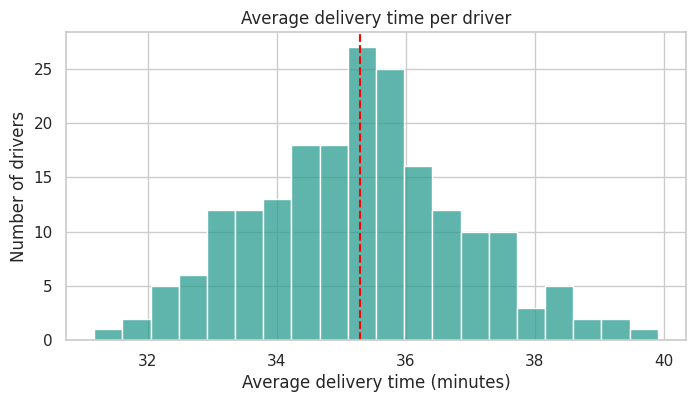

In [75]:
# Q25: how spread out are the drivers' average delivery times?
plt.figure(figsize=(8, 4))
sns.histplot(drivers["avg_delivery_time"], bins=20, color="#2a9d8f")

# red dashed line = average of all drivers
plt.axvline(drivers["avg_delivery_time"].mean(), color="red", linestyle="--")

plt.title("Average delivery time per driver")
plt.xlabel("Average delivery time (minutes)")
plt.ylabel("Number of drivers")
plt.show()

**Observation (Q24):**
- The busiest driver is DRV_0064 with 308 completed orders. The top 10
  drivers handle between 292 and 308 orders each.
- Orders are shared evenly: every driver handles between 192 and 308 orders
  (median 242), and the top 10 drivers handle only 6.1% of all orders.
- There is no concentration problem for drivers, unlike customers.

**Observation (Q25):**
- Experience groups differ by only 0.23 minutes and rating groups by 0.64
  minutes in average delivery time, so no group is meaningfully slower.
- Individual driver averages range from 32.3 to 39.1 minutes, but most are
  between 34.3 and 35.9.
- The slowest driver, DRV_0043 (39.05 min), has 55 months of experience and
  a 4.8 rating, so experience and rating do not predict slowness.
- Delivery time depends more on distance, preparation time, weather and
  traffic than on the driver.

## Traffic Analysis

In [76]:
# Q26, Q27, Q28, Q30: how does traffic affect delivery time and ETA?
traffic_order = ["Low", "Medium", "High"]

traffic = completed.groupby("traffic_level").agg(
    orders=("order_id", "count"),
    avg_estimated_time=("estimated_delivery_time_minutes", "mean"),
    avg_delivery_time=("actual_delivery_time_minutes", "mean"),
    avg_delay=("delay_minutes", "mean"),
    late_rate=("late_delivery", "mean")
).reindex(traffic_order)

traffic["share_%"] = traffic["orders"] / traffic["orders"].sum() * 100
traffic["late_rate"] = traffic["late_rate"] * 100
traffic

,orders,avg_estimated_time,avg_delivery_time,avg_delay,late_rate,share_%
traffic_level,,,,,,
Low,5342,26.73,30.65,3.92,34.91,29.94
Medium,7025,30.81,35.05,4.24,36.26,39.38
High,5473,35.43,40.06,4.63,39.01,30.68


In [77]:
# Q28: What percentage of orders experience high traffic?
print("Orders in high traffic:", round(traffic.loc["High", "share_%"], 1), "%")

Orders in high traffic: 30.7 %


In [78]:
# Q26 and Q29: how much slower is high traffic compared with low traffic?
low = traffic.loc["Low", "avg_delivery_time"]
high = traffic.loc["High", "avg_delivery_time"]

print("Delivery time: high traffic is", round(high - low, 1), "minutes slower than low traffic")
print("That is", round((high / low - 1) * 100, 1), "% longer")
print("ETA: high traffic ETA is", round(traffic.loc["High", "avg_estimated_time"] - traffic.loc["Low", "avg_estimated_time"], 1), "minutes longer than low traffic ETA")

Delivery time: high traffic is 9.4 minutes slower than low traffic
That is 30.7 % longer
ETA: high traffic ETA is 8.7 minutes longer than low traffic ETA


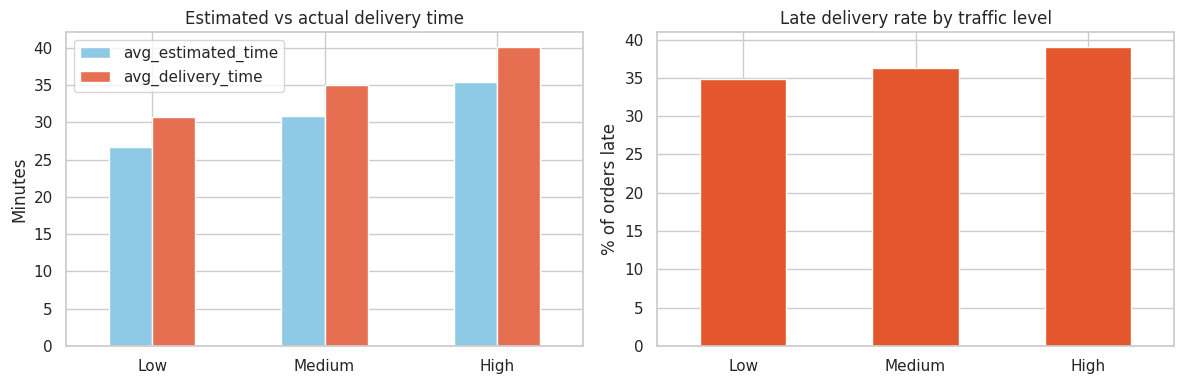

In [79]:
# Q26, Q29, Q30: promised time vs real time, and late deliveries, by traffic level
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

traffic[["avg_estimated_time", "avg_delivery_time"]].plot(kind="bar", ax=axes[0], color=["#8ecae6", "#e76f51"])
axes[0].set_title("Estimated vs actual delivery time")
axes[0].set_ylabel("Minutes")

traffic["late_rate"].plot(kind="bar", ax=axes[1], color="#e4572e")
axes[1].set_title("Late delivery rate by traffic level")
axes[1].set_ylabel("% of orders late")

for ax in axes:
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

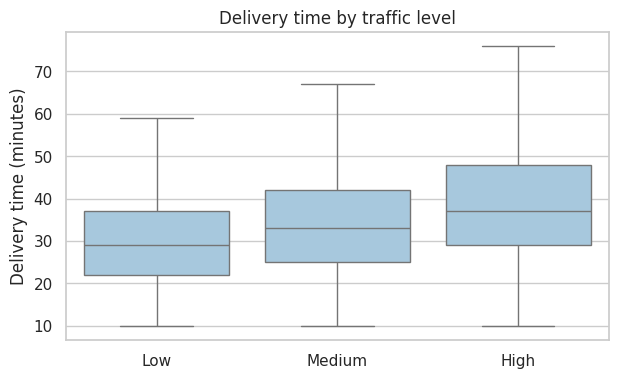

In [80]:
# Q26: spread of delivery times in each traffic level (extreme values hidden)
plt.figure(figsize=(7, 4))
sns.boxplot(data=completed, x="traffic_level", y="actual_delivery_time_minutes",
            order=traffic_order, showfliers=False, color="#9ecae6")

plt.title("Delivery time by traffic level")
plt.xlabel("")
plt.ylabel("Delivery time (minutes)")
plt.show()

**Observation (Q26 and Q27):**
- Traffic clearly increases delivery time: 30.6 minutes in low traffic, 35.0
  in medium traffic and 39.9 in high traffic.
- High traffic has the highest delivery time. It is 9.3 minutes (30%) slower
  than low traffic.

**Observation (Q28):**
- 30.4% of completed orders are delivered in high traffic (medium 39.1%,
  low 30.5%).

**Observation (Q29):**
- High traffic increases delays only slightly. The late rate rises from 34.7%
  (low) to 38.7% (high), and the average delay from 3.9 to 4.6 minutes.
- The ETA already increases by 8.6 minutes in high traffic, so the estimate
  accounts for most of the traffic effect.
- Even in low traffic 34.7% of orders are late, so traffic is not the main
  cause of lateness.

**Observation (Q30):**
- The average ETA is 26.7 minutes in low traffic, 30.8 in medium traffic and
  35.3 in high traffic.

## Weather Analysis

**Definition:** difficult weather = Rain or Storm.

In [81]:
# Q31, Q32, Q33: how does weather affect delivery time, ETA and delays?
weather_order = ["Clear", "Cloudy", "Rain", "Storm"]

weather = completed.groupby("weather").agg(
    orders=("order_id", "count"),
    avg_estimated_time=("estimated_delivery_time_minutes", "mean"),
    avg_delivery_time=("actual_delivery_time_minutes", "mean"),
    avg_delay=("delay_minutes", "mean"),
    late_rate=("late_delivery", "mean")
).reindex(weather_order)

weather["share_%"] = weather["orders"] / weather["orders"].sum() * 100
weather["late_rate"] = weather["late_rate"] * 100
weather

,orders,avg_estimated_time,avg_delivery_time,avg_delay,late_rate,share_%
weather,,,,,,
Clear,10128,31.18,33.74,2.56,24.52,56.77
Cloudy,4559,30.69,35.01,4.33,38.85,25.55
Rain,2663,30.86,39.42,8.56,69.77,14.93
Storm,490,31.21,46.67,15.46,88.78,2.75


In [82]:
# Q32 and Q34: compare normal weather (Clear, Cloudy) with difficult weather (Rain, Storm)
completed["weather_group"] = np.where(completed["weather"].isin(["Rain", "Storm"]),
                                      "Difficult (Rain/Storm)", "Normal (Clear/Cloudy)")

weather_group = completed.groupby("weather_group").agg(
    orders=("order_id", "count"),
    avg_estimated_time=("estimated_delivery_time_minutes", "mean"),
    avg_delivery_time=("actual_delivery_time_minutes", "mean"),
    avg_delay=("delay_minutes", "mean"),
    late_rate=("late_delivery", "mean")
).reindex(["Normal (Clear/Cloudy)", "Difficult (Rain/Storm)"])

weather_group["share_%"] = weather_group["orders"] / weather_group["orders"].sum() * 100
weather_group["late_rate"] = weather_group["late_rate"] * 100
weather_group

,orders,avg_estimated_time,avg_delivery_time,avg_delay,late_rate,share_%
weather_group,,,,,,
Normal (Clear/Cloudy),14687,31.03,34.14,3.11,28.96,82.33
Difficult (Rain/Storm),3153,30.91,40.55,9.63,72.72,17.67


In [83]:
# Q34: What percentage of deliveries occur under difficult weather conditions?
print("Orders in difficult weather:", round(weather_group.loc["Difficult (Rain/Storm)", "share_%"], 1), "%")

Orders in difficult weather: 17.7 %


In [84]:
# Q31 and Q33: storm compared with clear weather
clear = weather.loc["Clear"]
storm = weather.loc["Storm"]

print("Delivery time: storm is", round(storm["avg_delivery_time"] - clear["avg_delivery_time"], 1), "minutes slower than clear weather")
print("That is", round((storm["avg_delivery_time"] / clear["avg_delivery_time"] - 1) * 100, 1), "% longer")
print("ETA: storm ETA is only", round(storm["avg_estimated_time"] - clear["avg_estimated_time"], 1), "minutes longer than clear-weather ETA")

Delivery time: storm is 12.9 minutes slower than clear weather
That is 38.3 % longer
ETA: storm ETA is only 0.0 minutes longer than clear-weather ETA


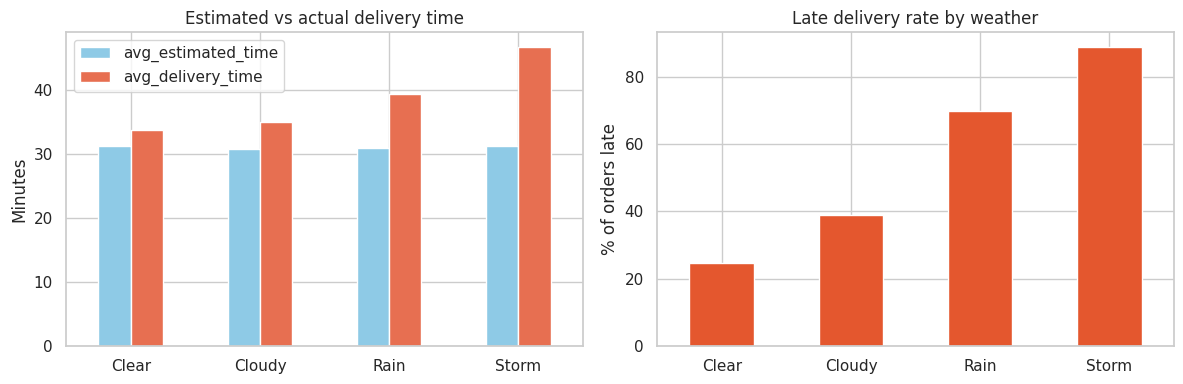

In [85]:
# Q31, Q32, Q33: promised time vs real time, and late deliveries, by weather
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

weather[["avg_estimated_time", "avg_delivery_time"]].plot(kind="bar", ax=axes[0], color=["#8ecae6", "#e76f51"])
axes[0].set_title("Estimated vs actual delivery time")
axes[0].set_ylabel("Minutes")

weather["late_rate"].plot(kind="bar", ax=axes[1], color="#e4572e")
axes[1].set_title("Late delivery rate by weather")
axes[1].set_ylabel("% of orders late")

for ax in axes:
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

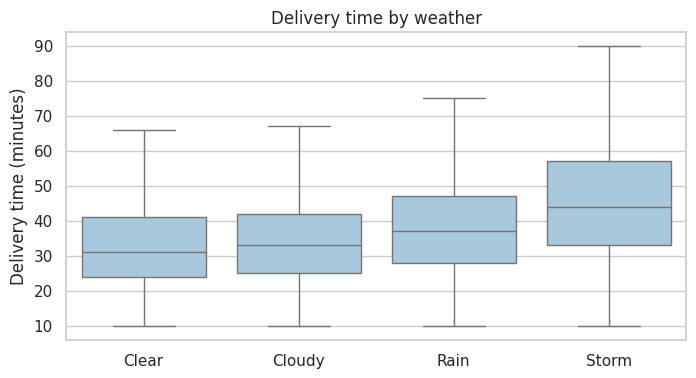

In [86]:
# Q31: spread of delivery times in each weather condition (extreme values hidden)
plt.figure(figsize=(8, 4))
sns.boxplot(data=completed, x="weather", y="actual_delivery_time_minutes",
            order=weather_order, showfliers=False, color="#9ecae6")

plt.title("Delivery time by weather")
plt.xlabel("")
plt.ylabel("Delivery time (minutes)")
plt.show()

**Observation (Q31):**
- Weather strongly affects delivery time: 33.6 minutes in clear weather,
  35.1 in cloudy, 39.2 in rain and 47.1 in storms.
- A storm delivery is 13.5 minutes (40%) slower than a clear-weather one.

**Observation (Q32):**
- Bad weather greatly increases delays. The late rate is 24.5% in clear
  weather, 38.8% in cloudy, 69.2% in rain and 89.2% in storms.
- In difficult weather (rain or storm) the late rate is 72.1% against 28.9%
  in normal weather, and the average delay is 9.5 against 3.1 minutes.

**Observation (Q33):**
- The highest average ETA is in storms (31.4 minutes), but the ETA is almost
  the same in all weather conditions (30.7 to 31.4 minutes).
- The ETA does not account for the weather: in a storm the real time rises
  by 13.5 minutes while the ETA rises by only 0.4 minutes.

**Observation (Q34):**
- 17.7% of completed orders (8,694) are delivered in difficult weather
  (rain 15.1%, storm 2.6%).

**Key insight:** weather is a much bigger cause of late deliveries than
traffic, and it should be added to the ETA calculation.

## Financial Analysis

### Part 1: Totals, Discounts, Tax and Fees

In [87]:
# Q35 to Q39: total order value, average order value, discounts, tax and delivery fees
print("Q35 Total order value  :", round(completed["order_total"].sum(), 2))
print("Q36 Average order value:", round(completed["order_total"].mean(), 2))
print("    Median order value :", round(completed["order_total"].median(), 2))
print("Q37 Total discount     :", round(completed["discount_amount"].sum(), 2))
print("Q38 Total tax          :", round(completed["tax_amount"].sum(), 2))
print("Q39 Total delivery fees:", round(completed["delivery_fee"].sum(), 2))
print("    Total service fees :", round(completed["service_fee"].sum(), 2))
print("    Total tips         :", round(completed["tip_amount"].sum(), 2))

Q35 Total order value  : 675779.55
Q36 Average order value: 37.88
    Median order value : 28.27
Q37 Total discount     : 24813.2
Q38 Total tax          : 72992.45
Q39 Total delivery fees: 55384.5
    Total service fees : 26037.51
    Total tips         : 28391.05


In [88]:
# the total order value broken into its parts, with each part's share of the total
breakdown = pd.Series({
    "Gross food value (before discount)": completed["subtotal"].sum(),
    "Discounts given": -completed["discount_amount"].sum(),
    "Net food value (after discount)": completed["net_food_value"].sum(),
    "Tax collected": completed["tax_amount"].sum(),
    "Service fees": completed["service_fee"].sum(),
    "Delivery fees": completed["delivery_fee"].sum(),
    "TOTAL ORDER VALUE": completed["order_total"].sum()
}).to_frame("amount")

breakdown["% of total"] = breakdown["amount"] / completed["order_total"].sum() * 100
breakdown

,amount,% of total
Gross food value (before discount),"546,178.36",80.82
Discounts given,"-24,813.20",-3.67
Net food value (after discount),"521,365.16",77.15
Tax collected,"72,992.45",10.80
Service fees,"26,037.51",3.85
Delivery fees,"55,384.50",8.20
TOTAL ORDER VALUE,"675,779.55",100.00


In [89]:
# check: net food + tax + service + delivery should equal the total (a tiny rounding difference is normal)
parts = (completed["net_food_value"].sum() + completed["tax_amount"].sum()
         + completed["service_fee"].sum() + completed["delivery_fee"].sum())
print("Difference:", round(abs(parts - completed["order_total"].sum()), 2))

# tax and service fee as a % of the food value after discount
print("Tax as % of net food value    :", round(completed["tax_amount"].sum() / completed["net_food_value"].sum() * 100, 1), "%")
print("Service fee as % of net food  :", round(completed["service_fee"].sum() / completed["net_food_value"].sum() * 100, 1), "%")

Difference: 0.07
Tax as % of net food value    : 14.0 %
Service fee as % of net food  : 5.0 %


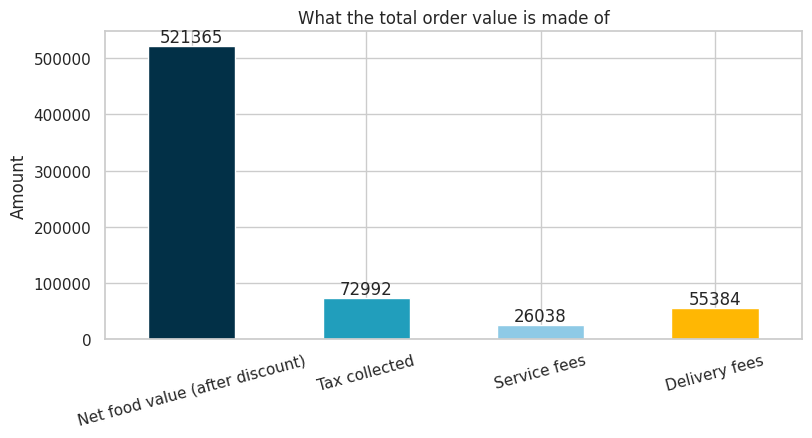

In [90]:
# Q35: chart of what the total order value is made of
parts_chart = breakdown.loc[["Net food value (after discount)", "Tax collected", "Service fees", "Delivery fees"], "amount"]

ax = parts_chart.plot(kind="bar", figsize=(9, 4), color=["#023047", "#219ebc", "#8ecae6", "#ffb703"])
for i, v in enumerate(parts_chart):
    ax.text(i, v, str(round(v)), ha="center", va="bottom")

plt.title("What the total order value is made of")
plt.xlabel("")
plt.ylabel("Amount")
plt.xticks(rotation=15)
plt.show()

In [91]:
# Q37: how often are discounts given, and how big are they?
with_discount = completed[completed["discount_percent"] > 0]

print("Orders with a discount:", round(len(with_discount) / len(completed) * 100, 1), "%")
print("Average discount on those orders:", round(with_discount["discount_amount"].mean(), 2))
print("Discount as % of gross food value:", round(completed["discount_amount"].sum() / completed["subtotal"].sum() * 100, 2), "%")

Orders with a discount: 40.1 %
Average discount on those orders: 3.47
Discount as % of gross food value: 4.54 %


In [92]:
# Q39: how many orders have free delivery, and what do the others pay?
print("Orders with free delivery:", round((completed["delivery_fee"] == 0).mean() * 100, 1), "%")
print("Average delivery fee on paid orders:", round(completed.loc[completed["delivery_fee"] > 0, "delivery_fee"].mean(), 2))

Orders with free delivery: 29.0 %
Average delivery fee on paid orders: 4.37


**Observation (Q35 and Q36):**
- The total order value of completed orders is 1,874,176.57.
- The average order value is 38.15, but the median is only 28.36, because a
  few very large orders (up to 443.21) raise the average.

**Observation (Q37):**
- Total discount given is 69,029.82, about 4.55% of the gross food value.
- 39.9% of orders receive a discount, averaging 3.52 per discounted order.

**Observation (Q38 and Q39):**
- Total tax collected is 202,710.15, exactly 14% of the food value after
  discount.
- Total delivery fees are 151,161.80. 29.4% of orders have free delivery
  (all Premium orders), and the rest pay 4.36 on average.
- Service fees total 72,394.70 (5% of the food value), and tips total
  79,106.27 (not included in the order total).

**Composition:** food is 77% of the total order value, tax 11%, delivery
fees 8% and service fees 4%.

### Revenue by Customer Type and Cuisine, and the Effect of Discounts

In [93]:
# Q40: Which loyalty tier has the highest order value?
q40 = completed.groupby("customer_type")["order_total"].agg(
    total_order_value="sum", avg_order_value="mean", orders="count"
).reindex(["New", "Regular", "Premium"])

q40["share_%"] = q40["total_order_value"] / q40["total_order_value"].sum() * 100
display(q40)

print("Highest TOTAL order value  :", q40["total_order_value"].idxmax())
print("Highest AVERAGE order value:", q40["avg_order_value"].idxmax())

,total_order_value,avg_order_value,orders,share_%
customer_type,,,,
New,"146,335.48",39.93,3665,21.65
Regular,"354,912.14",39.40,9009,52.52
Premium,"174,531.93",33.78,5166,25.83


Highest TOTAL order value  : Regular
Highest AVERAGE order value: New


In [94]:
# Q41: Which cuisine generates the highest revenue?
q41 = completed.groupby("restaurant_primary_category").agg(
    orders=("order_id", "count"),
    revenue=("order_total", "sum"),
    avg_order_value=("order_total", "mean"),
    avg_items=("items_count", "mean")
).sort_values("revenue", ascending=False)

q41["share_%"] = q41["revenue"] / q41["revenue"].sum() * 100
q41

,orders,revenue,avg_order_value,avg_items,share_%
restaurant_primary_category,,,,,
Burger,5706,"193,396.31",33.89,2.89,28.62
Local,4631,"173,111.47",37.38,2.95,25.62
Dessert,3436,"133,600.06",38.88,2.89,19.77
Asian,1316,"59,354.76",45.10,2.86,8.78
Pizza,1462,"59,189.17",40.49,2.86,8.76
Healthy,1289,"57,127.78",44.32,2.76,8.45


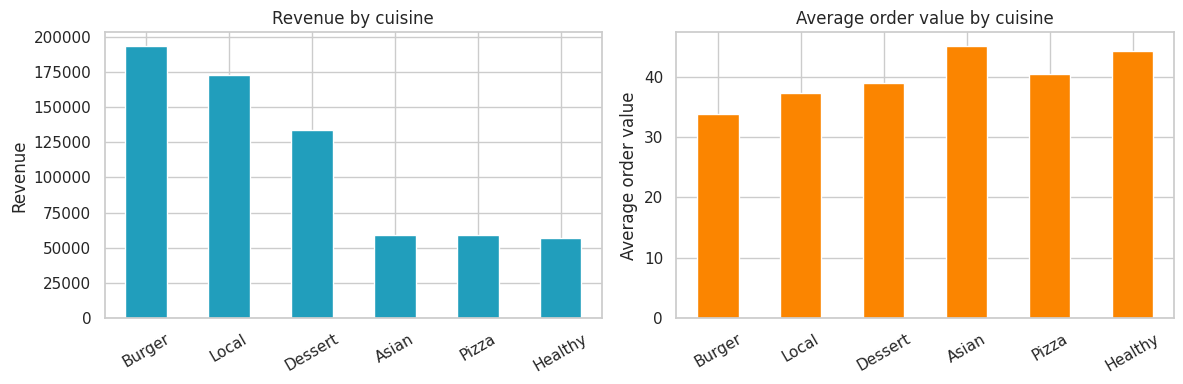

In [95]:
# Q41: revenue (left) and average order value (right) by cuisine
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

q41["revenue"].plot(kind="bar", ax=axes[0], color="#219ebc")
axes[0].set_title("Revenue by cuisine")
axes[0].set_ylabel("Revenue")

q41["avg_order_value"].plot(kind="bar", ax=axes[1], color="#fb8500")
axes[1].set_title("Average order value by cuisine")
axes[1].set_ylabel("Average order value")

for ax in axes:
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

In [96]:
# Q42: Does discount level affect order value?
q42 = completed.groupby("discount_percent").agg(
    orders=("order_id", "count"),
    avg_items=("items_count", "mean"),
    avg_subtotal=("subtotal", "mean"),
    median_subtotal=("subtotal", "median"),
    avg_discount_amount=("discount_amount", "mean"),
    avg_order_total=("order_total", "mean")
)

q42["share_%"] = q42["orders"] / q42["orders"].sum() * 100
q42

,orders,avg_items,avg_subtotal,median_subtotal,avg_discount_amount,avg_order_total,share_%
discount_percent,,,,,,,
0,10680,2.89,30.65,20.77,0.00,39.59,59.87
5,2130,2.92,30.60,20.69,1.53,37.73,11.94
10,2121,2.90,30.49,23.60,3.05,35.69,11.89
15,1799,2.85,30.22,22.02,4.53,33.65,10.08
20,1110,2.92,31.24,24.23,6.25,32.76,6.22


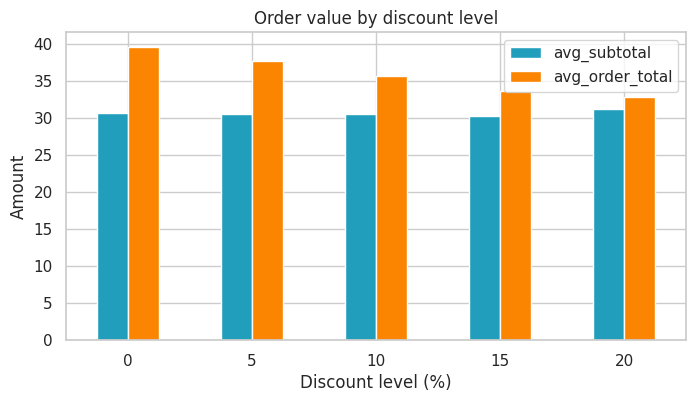

In [97]:
# Q42: food value before the discount vs the amount the customer pays, by discount level
q42[["avg_subtotal", "avg_order_total"]].plot(kind="bar", figsize=(8, 4), color=["#219ebc", "#fb8500"])

plt.title("Order value by discount level")
plt.xlabel("Discount level (%)")
plt.ylabel("Amount")
plt.xticks(rotation=0)
plt.show()

In [98]:
# Q42: relationship between discount level and order value (one number each)
display(completed[["discount_percent", "subtotal", "order_total"]].corr())

# % of each customer type's orders at each discount level
display(pd.crosstab(completed["customer_type"], completed["discount_percent"], normalize="index").reindex(["New", "Regular", "Premium"]) * 100)

,discount_percent,subtotal,order_total
discount_percent,1.00,0.00,-0.08
subtotal,0.00,1.00,0.99
order_total,-0.08,0.99,1.00


discount_percent,0,5,10,15,20
customer_type,,,,,
New,59.73,12.47,12.01,9.50,6.30
Regular,59.81,11.95,11.89,10.43,5.92
Premium,60.07,11.54,11.81,9.89,6.70


**Observation (Q40):**
- Regular customers have the highest total order value (977,149.10, 52.1% of
  the total) because they place the most orders.
- New customers have the highest average order value (40.72). Premium has
  the lowest (33.87) because Premium orders have free delivery.

**Observation (Q41):**
- Burger generates the most revenue (538,745.37, 28.8%), followed by Local
  (24.9%) and Dessert (19.5%).
- Burger wins on volume: it has the most orders but the lowest average order
  value (33.87).
- Healthy (46.31) and Asian (46.23) have the highest average order values with
  the same number of items (about 2.9), so their food costs more per item.
- Asian earns more than Pizza despite having fewer orders.

**Observation (Q42):**
- Higher discounts reduce what customers pay: the average order total falls
  from 39.64 (no discount) to 33.72 (20% discount).
- Discounts do not clearly increase order size: the average food value before
  discount stays between 30.7 and 32.2 and the correlation is 0.01.
- Discounts are spread equally across customer types, so Premium customers do
  not receive more discounts than New customers.
- Total discounts cost 69,029.82. A small test with and without discounts
  would show whether they are worth the cost.

## ETA Analysis

In [99]:
# Q43: What is the average ETA?
eta = completed["estimated_delivery_time_minutes"]

print("Q43 Average ETA :", round(eta.mean(), 2), "min")
print("    Median ETA  :", eta.median(), "min")
print("    Minimum ETA :", eta.min(), "min")
print("    Maximum ETA :", eta.max(), "min")

Q43 Average ETA : 31.01 min
    Median ETA  : 28.5 min
    Minimum ETA : 8.0 min
    Maximum ETA : 120.0 min


In [100]:
# promised time (ETA) and real time side by side
completed[["estimated_delivery_time_minutes", "actual_delivery_time_minutes"]].describe()

,estimated_delivery_time_minutes,actual_delivery_time_minutes
count,"17,840.00","17,840.00"
mean,31.01,35.27
std,12.80,14.65
min,8.00,10.00
25%,22.00,25.00
50%,28.50,33.00
75%,37.00,42.00
max,120.00,172.00


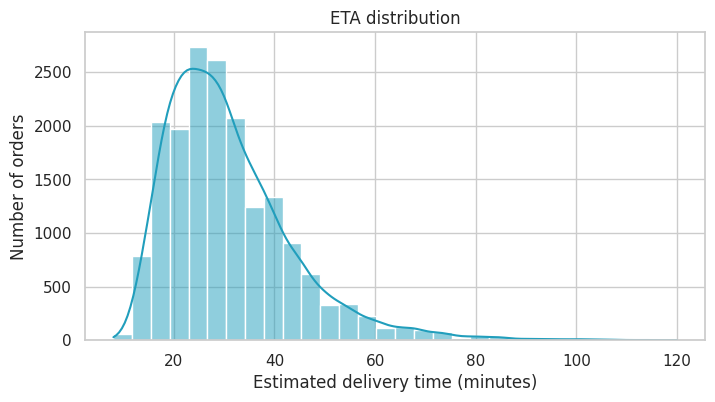

In [101]:
# Q43: how are the ETAs spread out?
plt.figure(figsize=(8, 4))
sns.histplot(eta, bins=30, kde=True, color="#219ebc")

plt.title("ETA distribution")
plt.xlabel("Estimated delivery time (minutes)")
plt.ylabel("Number of orders")
plt.show()

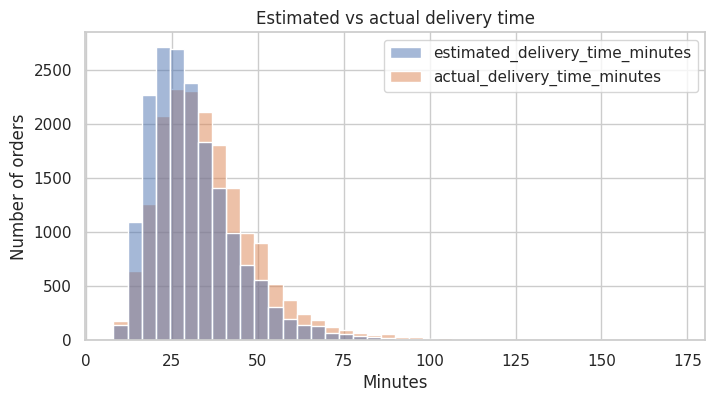

In [102]:
# promised time vs real time on the same chart
plt.figure(figsize=(8, 4))
sns.histplot(data=completed[["estimated_delivery_time_minutes", "actual_delivery_time_minutes"]], bins=40, alpha=0.5)

plt.title("Estimated vs actual delivery time")
plt.xlabel("Minutes")
plt.ylabel("Number of orders")
plt.show()

In [103]:
# delay_minutes = actual time - estimated time, .abs() ignores the + or - sign
print("Average error (ignoring + or -):", round(completed["delay_minutes"].abs().mean(), 2), "min")
print("Orders within 5 min of the ETA :", round((completed["delay_minutes"].abs() <= 5).mean() * 100, 1), "%")
print("Orders within 10 min of the ETA:", round((completed["delay_minutes"].abs() <= 10).mean() * 100, 1), "%")
print("Orders slower than the ETA     :", round((completed["delay_minutes"] > 0).mean() * 100, 1), "%")

Average error (ignoring + or -): 5.28 min
Orders within 5 min of the ETA : 61.5 %
Orders within 10 min of the ETA: 89.2 %
Orders slower than the ETA     : 76.3 %


In [104]:
# how strongly does the ETA move with other columns?
print("ETA vs distance        :", round(eta.corr(completed["distance_km"]), 2))
print("ETA vs preparation time:", round(eta.corr(completed["restaurant_preparation_time_minutes"]), 2))
print("ETA vs actual time     :", round(eta.corr(completed["actual_delivery_time_minutes"]), 2))

ETA vs distance        : 0.81
ETA vs preparation time: 0.44
ETA vs actual time     : 0.93


**Observation (Q43):**
- The average ETA is 30.92 minutes and the median is 28 minutes. The average
  is higher because a few very long ETAs (up to 128 minutes) pull it up.
- ETAs range from 8 to 128 minutes, and half of the orders are between 22 and
  37 minutes. About 57% of orders have an ETA of 30 minutes or less.
- The distribution has a long tail to the right.
- The real delivery time is longer and more spread out: average 35.15 minutes,
  median 33, maximum 172.

**ETA quality:**
- The ETA follows the real time well (correlation 0.93), but it is too
  optimistic: 75.9% of orders take longer than the ETA, by 4.2 minutes on
  average.
- The average error is 5.2 minutes. 61.6% of orders arrive within 5 minutes
  of the ETA and 89.3% within 10 minutes.
- The ETA is mainly based on distance (correlation 0.81) and preparation time
  (0.45). It does not account for weather.

## Delivery Delay Analysis

In [105]:
# Q8: how many orders are delayed (more than 5 minutes late)?
print(completed["is_delayed"].value_counts())
print("Delayed orders:", round(completed["is_delayed"].mean() * 100, 1), "%")

is_delayed
0.00    11293
1.00     6547
Name: count, dtype: int64
Delayed orders: 36.7 %


In [106]:
# Q8: keep only the delayed orders and look at their delay
delayed = completed[completed["delay_minutes"] > 5]

print("Average delay of delayed orders:", round(delayed["delay_minutes"].mean(), 2), "min")
print("Median delay of delayed orders :", delayed["delay_minutes"].median(), "min")
print("Longest delay                  :", delayed["delay_minutes"].max(), "min")
print("Average delay of ALL orders    :", round(completed["delay_minutes"].mean(), 2), "min")

Average delay of delayed orders: 9.73 min
Median delay of delayed orders : 9.0 min
Longest delay                  : 75.0 min
Average delay of ALL orders    : 4.26 min


In [107]:
# sort the delayed orders into groups by how late they are
severity = pd.cut(delayed["delay_minutes"], [5, 10, 15, 20, 100],
                  labels=["6-10 min", "11-15 min", "16-20 min", "20+ min"])

severity_table = severity.value_counts().sort_index().to_frame("orders")
severity_table["share_of_delayed_%"] = severity_table["orders"] / severity_table["orders"].sum() * 100
severity_table

,orders,share_of_delayed_%
delay_minutes,,
6-10 min,4632,70.75
11-15 min,1358,20.74
16-20 min,359,5.48
20+ min,198,3.02


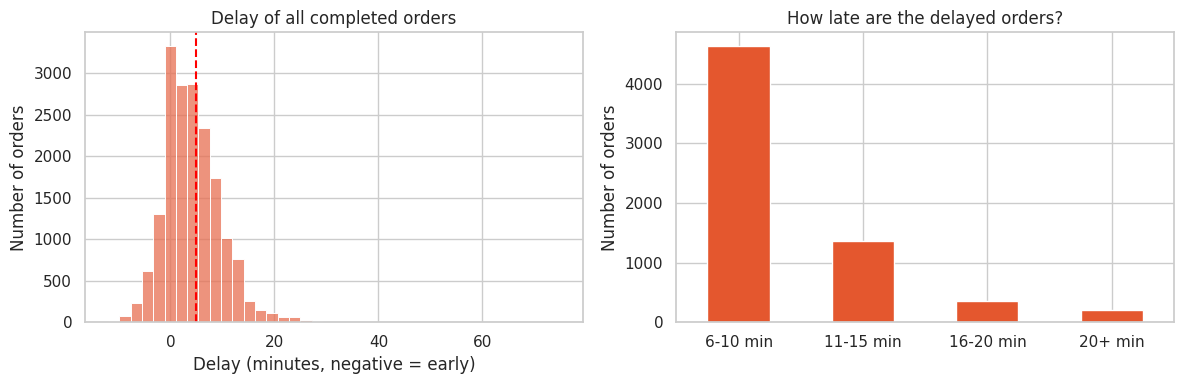

In [108]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(completed["delay_minutes"], bins=40, color="#e76f51", ax=axes[0])
axes[0].set_title("Delay of all completed orders")
axes[0].set_xlabel("Delay (minutes, negative = early)")
axes[0].set_ylabel("Number of orders")

# red dashed line = the 5-minute limit: orders to the right of it are "delayed"
axes[0].axvline(5, color="red", linestyle="--")

severity_table["orders"].plot(kind="bar", ax=axes[1], color="#e4572e")
axes[1].set_title("How late are the delayed orders?")
axes[1].set_xlabel("")
axes[1].set_ylabel("Number of orders")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

In [109]:
# optional: late rate by delivery distance
distance_late = completed.groupby("distance_band", observed=True).agg(
    orders=("order_id", "count"),
    avg_delivery_time=("actual_delivery_time_minutes", "mean"),
    avg_delay=("delay_minutes", "mean"),
    late_rate=("late_delivery", "mean")
)

distance_late["late_rate"] = distance_late["late_rate"] * 100
distance_late

,orders,avg_delivery_time,avg_delay,late_rate
distance_band,,,,
0-2 km,1871,22.72,3.16,28.54
2-5 km,9660,30.04,3.79,34.60
5-10 km,5378,43.33,5.06,41.69
10+ km,931,68.17,6.69,46.08


**Observation (Q8):**
- 17,968 completed orders (36.6%) are delayed by more than 5 minutes, and
  31,164 (63.4%) are not.
- A delayed order is on average 9.7 minutes late (median 8 minutes), and the
  longest delay is 75 minutes. The average delay across all orders is 4.23
  minutes.

**Delay severity:**
- Most delays are moderate: 70.8% of delayed orders are 6 to 10 minutes late
  and 21.1% are 11 to 15 minutes late.
- Serious delays are rare: only 8.1% of delayed orders (1,452 orders, about
  3% of all completed orders) are more than 15 minutes late.

**Distance:**
- Longer trips are late more often: the late rate rises from 29.4% under 2 km
  to 46.8% above 10 km. Delivery time triples, but the delay grows by only
  about 4 minutes, so the ETA already accounts for distance.

## Correlation Analysis

In [110]:
# correlation only works with numbers, so we give each level a score (a higher number = a harder condition)
completed["traffic_score"] = completed["traffic_level"].map({"Low": 1, "Medium": 2, "High": 3})
completed["weather_score"] = completed["weather"].map({"Clear": 1, "Cloudy": 2, "Rain": 3, "Storm": 4})

completed[["traffic_level", "traffic_score", "weather", "weather_score"]].head()

,traffic_level,traffic_score,weather,weather_score
0,Medium,2,Rain,3
1,High,3,Cloudy,2
2,High,3,Cloudy,2
3,Low,1,Cloudy,2
4,Medium,2,Rain,3


In [111]:
corr_columns = ["distance_km", "restaurant_preparation_time_minutes", "traffic_score", "weather_score",
                "items_count", "order_total", "discount_percent",
                "delivery_partner_experience_months", "delivery_partner_rating",
                "estimated_delivery_time_minutes", "actual_delivery_time_minutes", "delay_minutes"]

corr_matrix = completed[corr_columns].corr()
corr_matrix

,distance_km,restaurant_preparation_time_minutes,traffic_score,weather_score,items_count,order_total,discount_percent,delivery_partner_experience_months,delivery_partner_rating,estimated_delivery_time_minutes,actual_delivery_time_minutes,delay_minutes
distance_km,1.00,0.00,0.01,-0.02,0.01,0.04,-0.01,-0.01,0.00,0.81,0.77,0.17
restaurant_preparation_time_minutes,0.00,1.00,-0.01,0.01,0.74,0.86,-0.00,0.01,0.01,0.44,0.49,0.30
traffic_score,0.01,-0.01,1.00,0.00,-0.01,-0.01,0.00,0.01,0.01,0.26,0.25,0.05
weather_score,-0.02,0.01,0.00,1.00,0.00,0.01,0.00,0.00,0.00,-0.01,0.17,0.49
items_count,0.01,0.74,-0.01,0.00,1.00,0.80,-0.00,0.00,0.01,0.43,0.37,-0.01
order_total,0.04,0.86,-0.01,0.01,0.80,1.00,-0.08,0.01,0.00,0.52,0.46,0.01
discount_percent,-0.01,-0.00,0.00,0.00,-0.00,-0.08,1.00,-0.01,0.01,-0.01,-0.01,-0.00
delivery_partner_experience_months,-0.01,0.01,0.01,0.00,0.00,0.01,-0.01,1.00,0.06,-0.00,0.01,0.02
delivery_partner_rating,0.00,0.01,0.01,0.00,0.01,0.00,0.01,0.06,1.00,0.01,0.01,0.00
estimated_delivery_time_minutes,0.81,0.44,0.26,-0.01,0.43,0.52,-0.01,-0.00,0.01,1.00,0.93,0.15


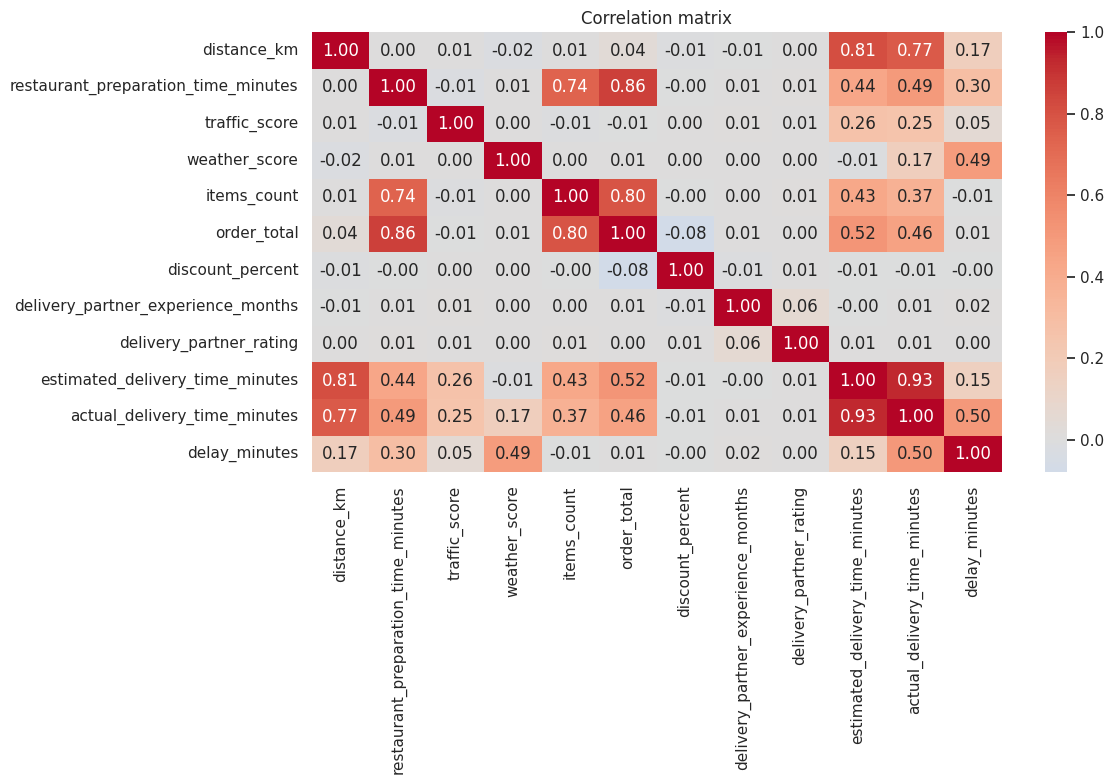

In [112]:
plt.figure(figsize=(12, 8))

# center=0 makes zero white: red = move together, blue = move in opposite directions
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0)

plt.title("Correlation matrix")
plt.tight_layout()
plt.show()

,actual_delivery_time_minutes
distance_km,0.77
restaurant_preparation_time_minutes,0.49
order_total,0.46
items_count,0.37
traffic_score,0.25
weather_score,0.17
delivery_partner_rating,0.01
discount_percent,-0.01
delivery_partner_experience_months,0.01


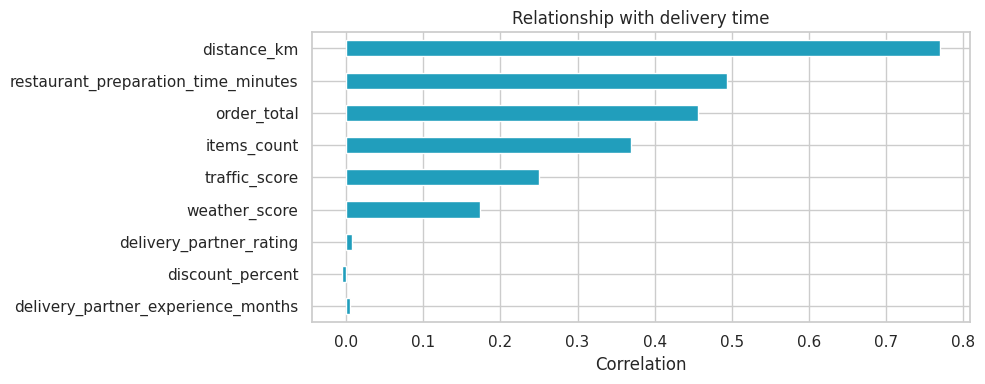

In [113]:
# we leave out the ETA and the delay, because they are built from the delivery time itself
time_corr = corr_matrix["actual_delivery_time_minutes"].drop(
    ["actual_delivery_time_minutes", "estimated_delivery_time_minutes", "delay_minutes"])

# key=abs sorts by size and ignores the + or - sign
time_corr = time_corr.sort_values(key=abs, ascending=False)
display(time_corr)

time_corr.sort_values(key=abs).plot(kind="barh", figsize=(10, 4), color="#219ebc")
plt.title("Relationship with delivery time")
plt.xlabel("Correlation")
plt.tight_layout()
plt.show()

,delay_minutes
weather_score,0.49
restaurant_preparation_time_minutes,0.30
distance_km,0.17
traffic_score,0.05
delivery_partner_experience_months,0.02
items_count,-0.01
order_total,0.01
delivery_partner_rating,0.00
discount_percent,-0.00


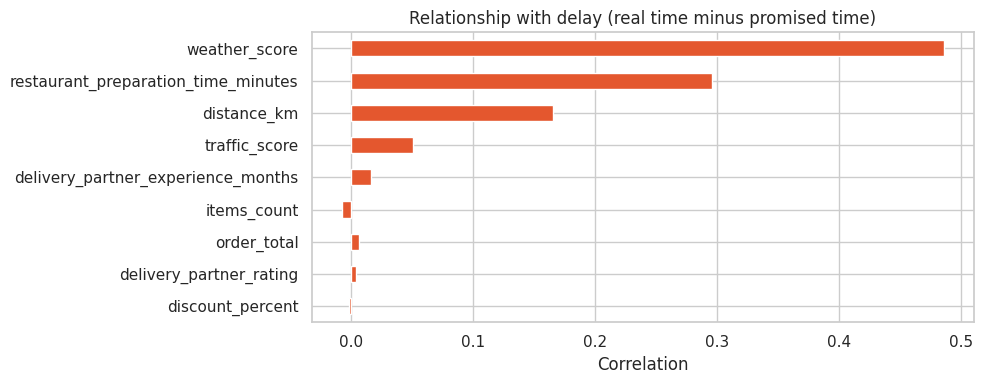

In [114]:
#what is linked to the lateness?
# delay_minutes = real time minus promised time, so this shows what makes orders later than promised
delay_corr = corr_matrix["delay_minutes"].drop(
    ["delay_minutes", "actual_delivery_time_minutes", "estimated_delivery_time_minutes"])

delay_corr = delay_corr.sort_values(key=abs, ascending=False)
display(delay_corr)

delay_corr.sort_values(key=abs).plot(kind="barh", figsize=(10, 4), color="#e4572e")
plt.title("Relationship with delay (real time minus promised time)")
plt.xlabel("Correlation")
plt.tight_layout()
plt.show()

In [115]:
eta = completed["estimated_delivery_time_minutes"]

print("Preparation time vs ETA      :", round(eta.corr(completed["restaurant_preparation_time_minutes"]), 3), " (Q47)")
print("Driver experience vs ETA     :", round(eta.corr(completed["delivery_partner_experience_months"]), 3), " (Q48)")
print("Traffic vs delivery time     :", round(completed["traffic_score"].corr(completed["actual_delivery_time_minutes"]), 3))
print("Order value vs delivery time :", round(completed["order_total"].corr(completed["actual_delivery_time_minutes"]), 3))
print("Discount vs order value      :", round(completed["discount_percent"].corr(completed["order_total"]), 3))
print("Weather vs ETA               :", round(completed["weather_score"].corr(eta), 3))

Preparation time vs ETA      : 0.439  (Q47)
Driver experience vs ETA     : -0.001  (Q48)
Traffic vs delivery time     : 0.25
Order value vs delivery time : 0.456
Discount vs order value      : -0.08
Weather vs ETA               : -0.01


**Observation (Q44):**
- Distance has the strongest relationship with delivery time (0.77), followed
  by preparation time (0.50), order value (0.46) and number of items (0.38).
  Traffic (0.25) and weather (0.17) are weaker.
- Driver experience, driver rating and discount have no relationship with
  delivery time (about 0).

**What causes late deliveries:**
- Weather has the strongest relationship with delay (0.48), followed by
  preparation time (0.29) and distance (0.18). Traffic is almost unrelated
  (0.05).
- Distance decides how long a delivery takes, but weather decides whether it
  is late, because the ETA already includes distance (correlation 0.81) but
  ignores weather (correlation -0.006).

**Observation (Q47 and Q48):**
- Preparation time has a moderate relationship with ETA (0.45).
- Driver experience has no relationship with ETA (-0.005).

**Other findings:**
- Preparation time, order value and number of items move together, because
  bigger orders take longer to prepare.
- Distance and preparation time are independent of each other.
- Correlation shows association, not causation.
- For ETA prediction, the most useful features are distance, preparation
  time, weather, traffic and number of items.

##  Statistical Outlier Analysis

In [116]:
# IQR method: returns the rows that are far outside the normal range of one column
def find_outliers(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1
    return data[(data[column] < Q1 - 1.5 * IQR) | (data[column] > Q3 + 1.5 * IQR)]

for col in ["order_total", "restaurant_preparation_time_minutes", "estimated_delivery_time_minutes",
            "actual_delivery_time_minutes", "discount_percent", "delivery_fee",
            "customer_age", "delivery_partner_rating", "restaurant_rating"]:
    print(col, ":", len(find_outliers(completed, col)))

order_total : 899
restaurant_preparation_time_minutes : 484
estimated_delivery_time_minutes : 627
actual_delivery_time_minutes : 585
discount_percent : 0
delivery_fee : 31
customer_age : 5
delivery_partner_rating : 67
restaurant_rating : 30


In [117]:
# Q49: the upper limit of a normal delivery time
q1 = completed["actual_delivery_time_minutes"].quantile(0.25)
q3 = completed["actual_delivery_time_minutes"].quantile(0.75)
upper = q3 + 1.5 * (q3 - q1)
print("Any delivery longer than", upper, "minutes is an outlier")

# 1 = outlier, 0 = normal
completed["outlier_delivery_time"] = (completed["actual_delivery_time_minutes"] > upper).astype(int)
long_orders = completed[completed["outlier_delivery_time"] == 1]
print("Outlier orders:", len(long_orders))

Any delivery longer than 67.5 minutes is an outlier
Outlier orders: 585


In [118]:
cols_to_show = ["order_id", "weather", "traffic_level", "distance_km",
                "estimated_delivery_time_minutes", "actual_delivery_time_minutes"]

long_orders.sort_values("actual_delivery_time_minutes", ascending=False)[cols_to_show].head(10)

,order_id,weather,traffic_level,distance_km,estimated_delivery_time_minutes,actual_delivery_time_minutes
4961,ORD_004962,Storm,High,19.70,97.00,172.00
10776,ORD_010777,Rain,High,20.00,107.00,143.00
6485,ORD_006486,Rain,High,15.00,107.00,130.00
16486,ORD_016487,Storm,High,13.90,76.00,129.00
1035,ORD_001036,Rain,High,13.90,97.00,129.00
6080,ORD_006081,Storm,High,14.00,73.00,124.00
12685,ORD_012686,Cloudy,High,20.00,120.00,123.00
6325,ORD_006326,Rain,Medium,17.10,104.00,123.00
14987,ORD_014988,Rain,Medium,14.80,96.00,120.00
16659,ORD_016660,Cloudy,High,15.60,103.00,120.00


In [119]:
# average of each factor: outlier orders vs all orders
compare_cols = ["distance_km", "restaurant_preparation_time_minutes",
                "estimated_delivery_time_minutes", "actual_delivery_time_minutes"]

display(pd.DataFrame({"outlier orders": long_orders[compare_cols].mean(),
                      "all orders": completed[compare_cols].mean()}))

print("Trips over 10 km:", round((long_orders["distance_km"] > 10).mean() * 100, 1), "% of the outliers")
print("Late rate of outlier orders:", round(long_orders["late_delivery"].mean() * 100, 1), "%")

# weather of the outlier orders, in %
long_orders["weather"].value_counts(normalize=True) * 100

,outlier orders,all orders
distance_km,12.38,4.76
restaurant_preparation_time_minutes,22.13,15.49
estimated_delivery_time_minutes,69.78,31.01
actual_delivery_time_minutes,81.54,35.27


Trips over 10 km: 71.5 % of the outliers
Late rate of outlier orders: 68.5 %


,proportion
weather,
Clear,40.17
Rain,25.98
Cloudy,24.44
Storm,9.40


## Data Quality Check: Order Concentration

## for my calculations start

In [120]:
# count the orders of each customer, most orders first
customer_orders = df["customer_id"].value_counts()

print("Customers                       :", len(customer_orders))
print("Median orders per customer      :", customer_orders.median())
print("Average orders per customer     :", round(customer_orders.mean(), 1))
print("Most orders by one customer     :", customer_orders.max())
print("Customers with only 1 order     :", (customer_orders == 1).sum())
print("Customers with more than 100    :", (customer_orders > 100).sum())
print("Top 5 customers' share of orders:", round(customer_orders.head(5).sum() / len(df) * 100, 1), "%")

Customers                       : 3030
Median orders per customer      : 1.0
Average orders per customer     : 6.0
Most orders by one customer     : 1617
Customers with only 1 order     : 1668
Customers with more than 100    : 19
Top 5 customers' share of orders: 24.9 %


In [121]:
customer_orders.head(10).to_frame("orders")

,orders
customer_id,
CUS_00001,1617
CUS_00004,856
CUS_00003,781
CUS_00002,726
CUS_00005,544
CUS_00006,452
CUS_00007,436
CUS_00008,392
CUS_00009,288


In [122]:
# group the customers by their number of orders
segments = pd.cut(customer_orders, [0, 1, 3, 10, 100, np.inf],
                  labels=["1 order", "2-3 orders", "4-10 orders", "11-100 orders", "100+ orders"])

freq = customer_orders.groupby(segments, observed=True).agg(["count", "sum"])
freq.columns = ["customers", "orders"]

freq["customers_%"] = freq["customers"] / freq["customers"].sum() * 100
freq["orders_%"] = freq["orders"] / freq["orders"].sum() * 100
freq

,customers,orders,customers_%,orders_%
count,,,,
1 order,1668,1668,55.05,9.19
2-3 orders,814,1853,26.86,10.20
4-10 orders,367,2085,12.11,11.48
11-100 orders,162,4597,5.35,25.31
100+ orders,19,7957,0.63,43.82


In [123]:
restaurant_orders = df["restaurant_id"].value_counts()
driver_orders = df["driver_id"].value_counts()

print("Restaurants                    :", len(restaurant_orders))
print("Most orders at one restaurant  :", restaurant_orders.max())
print("Fewest orders at one restaurant:", restaurant_orders.min())
print("Median orders per restaurant   :", restaurant_orders.median())
print("Top 5 restaurants' share       :", round(restaurant_orders.head(5).sum() / len(df) * 100, 1), "%")
print("Orders per driver              : from", driver_orders.min(), "to", driver_orders.max())

Restaurants                    : 250
Most orders at one restaurant  : 3238
Fewest orders at one restaurant: 3
Median orders per restaurant   : 19.0
Top 5 restaurants' share       : 44.4 %
Orders per driver              : from 64 to 125


## Save the Clean Datasets

In [124]:
# index=False stops pandas from adding an extra row-number column
df.to_csv("food_delivery_clean.csv", index=False)
completed.to_csv("food_delivery_completed.csv", index=False)

print("All orders:", df.shape)
print("Completed :", completed.shape)

All orders: (18160, 50)
Completed : (17840, 55)


In [125]:
# read the file back to make sure it saved correctly
check = pd.read_csv("food_delivery_completed.csv")

print(check.shape)
check["order_status"].value_counts()

(17840, 55)


,count
order_status,
Completed,17840


In [126]:
from google.colab import files

files.download("food_delivery_clean.csv")
files.download("food_delivery_completed.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>